# Time Series Analysis and Forecasting of Daily Website Visitors

**A complete beginner-to-intermediate time-series workflow: from a raw CSV file to model comparison, rolling-origin validation and a 28-day forecast with uncertainty.**

## Project Description

This project analyses **five-plus years of daily traffic data from an academic teaching-notes website (September 2014 – August 2020)** and forecasts the number of **daily unique visitors**.

Unlike a purely yearly-seasonal series such as temperature, website traffic is driven by **human behaviour**: it has a strong **day-of-week pattern**, plus slower time-of-year effects and a changing level. That makes it a good place to learn weekly seasonality, SARIMA, and several other seasonal methods.

| Item | Detail |
|---|---|
| **Dataset** | *Daily website visitors (time series regression)* on Kaggle, `bobnau/daily-website-visitors` |
| **Frequency** | Daily |
| **Target** | `unique_visits` – number of unique visitors per day |
| **Goal** | Compare 13 models on a chronological hold-out, validate with rolling origins and a significance test, then forecast the next 28 days |

**Teaching format used throughout:** *Concept → Why → Code → Result → Interpretation.*

## 2. Learning Objectives

By completing this notebook you will learn how to:

- Clean a real-world CSV (numbers stored as text, inconsistent column names) and build a proper **datetime index**
- Detect **weekly seasonality**, **yearly effects** and **trend** using plots, rolling statistics, resampling and decomposition
- Test **stationarity** (ADF) and decide between **regular** and **seasonal differencing**
- Read **ACF/PACF** plots when the data has a weekly cycle
- Split time-series data **chronologically** without leakage
- Build **baseline**, **ARIMA**, **SARIMA**, **Holt-Winters**, **STL**, **Theta**, regression and **machine-learning** forecasts
- Evaluate with MAE, RMSE and MAPE, using both a **one-shot hold-out** and a **rolling-origin (walk-forward)** evaluation
- Diagnose residuals and produce a **future forecast** with prediction intervals

## Dataset Overview

| Question | Answer |
|---|---|
| **Name** | Daily website visitors (time series regression) |
| **Source** | Kaggle: https://www.kaggle.com/datasets/bobnau/daily-website-visitors |
| **What it represents** | Daily traffic counts for a statistical-forecasting teaching-notes website, collected over about five years |
| **Size** | 2,167 rows, from 2014-09-14 to 2020-08-19 (one row per day), according to the dataset page |
| **Measures** | Page loads, unique visitors, first-time visitors and returning visitors |
| **Target** | Unique visitors (`unique_visits`) |

**Definitions given by the dataset author**

- A visit is "unique" if a hit from the same IP address has not come within the last 6 hours.
- Returning visitors are identified by cookies; all others are first-time visitors.
- By definition, **unique visitors = first-time visitors + returning visitors**. We use this as a data-quality check.

**Why it is a good learning dataset**

- Clear date column and a count-valued target with thousands of observations.
- The author describes **day-of-week and time-of-year effects**, so seasonality at two scales can be explored.
- It is a realistic business-style forecasting problem (traffic and capacity planning).
- It requires real cleaning steps (counts stored as text, column names with dots).
- Weekly seasonality has a short period (7), so a **true SARIMA** model is practical, unlike yearly seasonality in daily data.

**Train/test design**

- The dataset is a single file, so we split it **chronologically**: the last 90 days are the **test set**, and everything before is the **training set**.
- The split is made right after cleaning. All exploration, statistical tests and parameter choices use **only the training data**.
- Forecasts are scored two ways: (1) a **one-shot 90-day forecast**, and (2) a **rolling-origin evaluation** with 14-day forecasts, which is closer to how forecasts are used in practice and less dependent on one lucky or unlucky period.

**What the final project predicts:** daily unique visitors for the **next 28 days** after the end of the data.

## 3. Import Libraries

Only libraries that are actually used are imported. Plot settings and constants are defined once so that every figure and every model uses the same values.

In [9]:
import warnings
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.tsa.forecasting.theta import ThetaModel
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning

from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ----- Reproducibility and global settings -----
RANDOM_SEED = 42            # fixed for the machine-learning models
np.random.seed(RANDOM_SEED)

FIGSIZE = (12, 5)           # consistent figure size
ALPHA = 0.05                # significance level for hypothesis tests
WEEKLY_PERIOD = 7           # weekly seasonality (days)
HOLDOUT_DAYS = 90           # size of the test set
ROLLING_HORIZON = 14        # forecast horizon of the rolling-origin evaluation (days)
FORECAST_HORIZON_DAYS = 28  # horizon of the final future forecast (days)
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

SAVE_FIGURES = True
# In the repository layout figures live next to data/; on Colab they go to ./figures
FIGURES_DIR = Path("../figures") if Path("../data").exists() else Path("figures")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = FIGSIZE
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="Non-stationary starting")
warnings.filterwarnings("ignore", message="Non-invertible starting")
warnings.filterwarnings("ignore", message="adfuller currently returns", category=FutureWarning)

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def finish_plot(filename=None):
    """Apply tight layout, optionally save the figure, then display it."""
    plt.tight_layout()
    if SAVE_FIGURES and filename:
        plt.savefig(FIGURES_DIR / f"{filename}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 4. Load the Dataset

**Concept:** Before any modelling we inspect the raw file: its size, columns, data types, missing values and duplicates.

**Why:** Real-world exports often store numbers as text, use awkward column names, or hide duplicated and missing dates. Finding these problems first prevents silent mistakes later.

**Data setup:** download the CSV from Kaggle and upload it to `/content/` (Google Colab) or place it in `data/`. The notebook searches those locations and also accepts any file whose name contains "visitors".

In [10]:
# Only needed on Google Colab (skipped automatically elsewhere)
try:
    from google.colab import drive
    # Mount to standard /content/drive location instead of a file name path
    drive.mount("/content/drive")
except ImportError:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
DATA_FILENAME = "daily-website-visitors.csv"


def find_data_file(filename, pattern="*visitors*.csv"):
    """Look for the dataset by exact name first, then by a flexible pattern."""
    # Added /content/sample_data to the search folders
    folders = [Path("/content/sample_data"), Path("/content"), Path("../data"), Path("data"), Path(".")]
    for folder in folders:
        candidate = folder / filename
        if candidate.exists() and not candidate.is_dir():
            return candidate
    for folder in folders:
        matches = sorted(folder.glob(pattern)) if folder.exists() else []
        for match in matches:
            if not match.is_dir():
                return match
    raise FileNotFoundError(
        f"'{filename}' not found. Upload it to /content or place it in the data/ folder."
    )


data_path = find_data_file(DATA_FILENAME)
print(f"Reading: {data_path}")
raw_df = pd.read_csv(data_path)

print("First 5 rows")
display(raw_df.head())
print("Last 5 rows")
display(raw_df.tail())

Reading: /content/sample_data/daily-website-visitors.csv
First 5 rows


,Row,Day,Day.Of.Week,Date,Page.Loads,Unique.Visits,First.Time.Visits,Returning.Visits
0,1,Sunday,1,9/14/2014,"2,146","1,582","1,430",152
1,2,Monday,2,9/15/2014,"3,621","2,528","2,297",231
2,3,Tuesday,3,9/16/2014,"3,698","2,630","2,352",278
3,4,Wednesday,4,9/17/2014,"3,667","2,614","2,327",287
4,5,Thursday,5,9/18/2014,"3,316","2,366","2,130",236


Last 5 rows


,Row,Day,Day.Of.Week,Date,Page.Loads,Unique.Visits,First.Time.Visits,Returning.Visits
2162,2163,Saturday,7,8/15/2020,"2,221","1,696","1,373",323
2163,2164,Sunday,1,8/16/2020,"2,724","2,037","1,686",351
2164,2165,Monday,2,8/17/2020,"3,456","2,638","2,181",457
2165,2166,Tuesday,3,8/18/2020,"3,581","2,683","2,184",499
2166,2167,Wednesday,4,8/19/2020,"2,064","1,564","1,297",267


In [12]:
print(f"Shape: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns\n")
print("Column names:", list(raw_df.columns), "\n")

print("Data types")
print(raw_df.dtypes, "\n")

print("Missing values per column")
print(raw_df.isna().sum(), "\n")

print(f"Duplicate rows: {raw_df.duplicated().sum()}\n")

print("Basic statistics (all columns)")
display(raw_df.describe(include="all").T)

Shape: 2167 rows x 8 columns

Column names: ['Row', 'Day', 'Day.Of.Week', 'Date', 'Page.Loads', 'Unique.Visits', 'First.Time.Visits', 'Returning.Visits'] 

Data types
Row                   int64
Day                  object
Day.Of.Week           int64
Date                 object
Page.Loads           object
Unique.Visits        object
First.Time.Visits    object
Returning.Visits     object
dtype: object 

Missing values per column
Row                  0
Day                  0
Day.Of.Week          0
Date                 0
Page.Loads           0
Unique.Visits        0
First.Time.Visits    0
Returning.Visits     0
dtype: int64 

Duplicate rows: 0

Basic statistics (all columns)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row,2167.0,NaN,NaN,NaN,1084.0,625.703338,1.0,542.5,1084.0,1625.5,2167.0
Day,2167,7,Sunday,310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Day.Of.Week,2167.0,NaN,NaN,NaN,3.997231,2.000229,1.0,2.0,4.0,6.0,7.0
Date,2167,2167,8/19/2020,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Page.Loads,2167,1756,"2,948",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unique.Visits,2167,1658,"2,667",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
First.Time.Visits,2167,1587,"3,133",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Returning.Visits,2167,663,552,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Interpretation

- **Shape and head/tail:** one row per day, from September 2014 to August 2020.
- **Data types:** the count columns may be read as **text (`object`/`string`)** if the file uses thousands separators such as `2,146`. Such values cannot be averaged or plotted until converted to numbers. `date` is also text and must be converted to a real date.
- **Missing values / duplicates:** the counts above tell us whether repairs are needed.
- **Basic statistics:** because some columns are text, `describe` shows counts and top values for them. After conversion we will inspect the real numeric ranges.

## 5. Data Cleaning and Preparation

**Concept:** Time-series data needs a *proper time index*: unique, sorted, gap-free timestamps with a known frequency, and numeric columns stored as numbers.

**Why:** Almost every time-series tool (rolling windows, resampling, ACF, ARIMA) assumes ordered observations at regular intervals. A missing day or a shuffled row silently breaks lags and seasonality.

Steps performed below:

1. Standardise column names (`Page.Loads` → `page_loads`).
2. Convert counts stored as text (with thousands separators) into numbers.
3. Convert `date` to `datetime`, sort chronologically, and check duplicates.
4. Check for impossible values (negative counts) and zero counts.
5. Verify the dataset's own definition: **unique = first-time + returning**.
6. Set `date` as the index and verify the daily frequency.
7. Repair missing values in the **target** with a time-aware method, only if needed.
8. Split chronologically into **train** and **test**.

The original `Row`, `Day` and `Day.Of.Week` columns are dropped: we derive the weekday ourselves from the date, which is always consistent.

In [13]:
COUNT_COLUMNS = ["page_loads", "unique_visits", "first_time_visits", "returning_visits"]


def standardise_column_names(columns):
    """Lower-case names and replace dots/spaces with underscores."""
    return [name.strip().lower().replace(".", "_").replace(" ", "_") for name in columns]


df = raw_df.copy()
df.columns = standardise_column_names(df.columns)

missing_columns = {"date", *COUNT_COLUMNS} - set(df.columns)
if missing_columns:
    raise KeyError(f"Expected columns not found: {sorted(missing_columns)}. Found: {list(df.columns)}")

# Counts may contain thousands separators ("2,146"); remove them and convert to numbers
for column in COUNT_COLUMNS:
    cleaned = df[column].astype("string").str.replace(",", "", regex=False)
    df[column] = pd.to_numeric(cleaned, errors="coerce")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
df = df[["date", *COUNT_COLUMNS]]

print(f"Duplicate dates          : {df['date'].duplicated().sum()}")
print(f"Values that became NaN   : {df[COUNT_COLUMNS].isna().sum().sum()} (should be 0 unless the raw data had gaps)")
print(f"Negative counts          : {(df[COUNT_COLUMNS] < 0).sum().sum()}")
print("Zero counts per column   :")
print((df[COUNT_COLUMNS] == 0).sum().to_string())

# The dataset author defines unique = first-time + returning
identity_gap = df["unique_visits"] - (df["first_time_visits"] + df["returning_visits"])
print(f"\nRows where unique != first-time + returning: {(identity_gap != 0).sum()}")
display(df[COUNT_COLUMNS].describe().T)

Duplicate dates          : 0
Values that became NaN   : 0 (should be 0 unless the raw data had gaps)
Negative counts          : 0
Zero counts per column   :
page_loads           0
unique_visits        0
first_time_visits    0
returning_visits     0

Rows where unique != first-time + returning: 0


,count,mean,std,min,25%,50%,75%,max
page_loads,2167.0,4116.989386,1350.977843,1002.0,3114.5,4106.0,5020.5,7984.0
unique_visits,2167.0,2943.646516,977.886472,667.0,2226.0,2914.0,3667.5,5541.0
first_time_visits,2167.0,2431.824181,828.704688,522.0,1830.0,2400.0,3038.0,4616.0
returning_visits,2167.0,511.822335,168.73637,133.0,388.5,509.0,626.5,1036.0


In [14]:
df = df.set_index("date")

expected_dates = pd.date_range(df.index.min(), df.index.max(), freq="D")
missing_dates = expected_dates.difference(df.index)
print(f"Date range    : {df.index.min().date()} to {df.index.max().date()}")
print(f"Expected days : {len(expected_dates)}")
print(f"Missing days  : {len(missing_dates)}")

df = df.asfreq("D")   # makes the daily frequency explicit
print(f"Index frequency: {df.index.freqstr}")

# The target must be complete. Interpolate in time only if gaps exist.
missing_target = df["unique_visits"].isna().sum()
if missing_target > 0:
    df["unique_visits"] = df["unique_visits"].interpolate(method="time")
    print(f"Interpolated {missing_target} missing target value(s) using time interpolation.")
else:
    print("No missing values in the target: no imputation needed.")

Date range    : 2014-09-14 to 2020-08-19
Expected days : 2167
Missing days  : 0
Index frequency: D
No missing values in the target: no imputation needed.


### Chronological train/test split

The last **90 days** are held out as the test set. We split **now**, before any exploration, so no analysis choice (differencing, seasonal period, model order) can be influenced by the test period.

In [15]:
full_series = df["unique_visits"]

train = full_series.iloc[:-HOLDOUT_DAYS]
test = full_series.iloc[-HOLDOUT_DAYS:]

# `series` is the TRAINING series used for exploration (sections 6-12).
series = train
train_df = df.iloc[:-HOLDOUT_DAYS]

print(f"Train: {train.index[0].date()} to {train.index[-1].date()} ({len(train)} days)")
print(f"Test : {test.index[0].date()} to {test.index[-1].date()} ({len(test)} days)")

Train: 2014-09-14 to 2020-05-21 (2077 days)
Test : 2020-05-22 to 2020-08-19 (90 days)


### Interpretation

- **Numeric conversion** is essential: without it, averages, plots and models would fail or silently misbehave.
- **Identity check:** if unique ≠ first-time + returning on some rows, it points to data-entry or logging inconsistencies. We report them but do not alter the data, because we cannot know which column is wrong.
- **Zero counts** on a busy site could signal tracking outages rather than real zero traffic, which is why they are counted separately.
- **Sorted, unique, gap-free dates** mean lag-based operations behave correctly: "one row back" always means "one day back".
- **No leakage by construction:** the test set is the last 90 days. Sections 6-12 use only `series` (the training data).

## 6. Exploratory Time Series Analysis

### 6.1 Full Time Series

**Concept:** A **line plot against time** is the first and most important time-series chart.

**Why:** It reveals trend, seasonality, unusual spikes and possible structural changes at a glance.

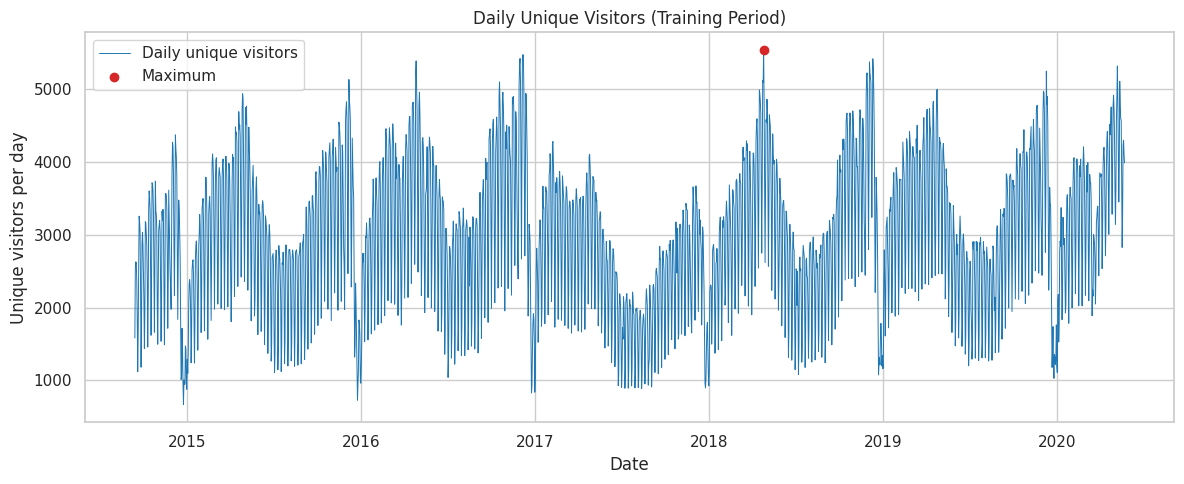

Highest day: 2018-04-25 (5,541 visitors)
Lowest day : 2014-12-25 (667 visitors)


In [16]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(series.index, series, linewidth=0.7, color="tab:blue", label="Daily unique visitors")
ax.scatter([series.idxmax()], [series.max()], color="tab:red", zorder=3, label="Maximum")
ax.set_title("Daily Unique Visitors (Training Period)")
ax.set_xlabel("Date")
ax.set_ylabel("Unique visitors per day")
ax.legend()
finish_plot("01_full_series")

print(f"Highest day: {series.idxmax().date()} ({series.max():,.0f} visitors)")
print(f"Lowest day : {series.idxmin().date()} ({series.min():,.0f} visitors)")

### Interpretation

- Look for a **dense, jagged texture**: this is the day-to-day (weekly) cycle, with many low and high days alternating.
- Look for **slower movements** in the overall level: periods of growth or decline, and possibly time-of-year effects.
- **Peaks and drops** that do not fit the pattern may be one-off events (for example a link being shared) or tracking problems. Forecasting models cannot predict these, so they limit achievable accuracy.
- **Structural changes** (a lasting level shift) would show as the whole series moving to a new range. Check the later rolling means for this.

### 6.2 Rolling Mean

**Concept:** A **rolling (moving) mean** averages the most recent *n* observations at each point in time.

**Why:** It smooths short-term noise so longer-term movement becomes visible. The window sets the timescale. We use:

- **7 days** – a full weekly cycle, so the weekday pattern averages out,
- **30 days** – approximately monthly behaviour,
- **365 days** – a full year, so yearly effects average out and the **trend** remains.

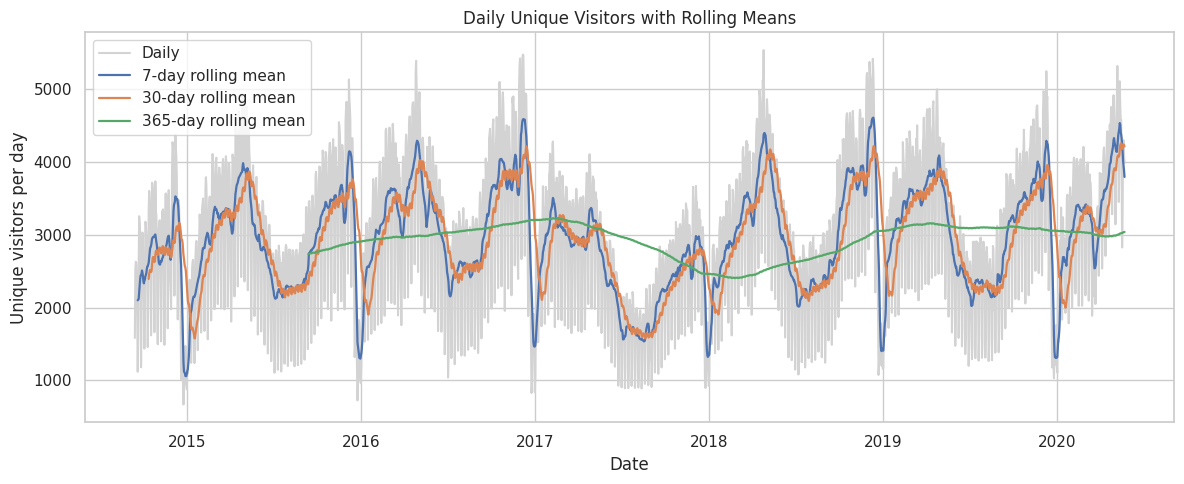

In [17]:
ROLLING_WINDOWS = [7, 30, 365]

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(series, color="lightgrey", label="Daily")
for window in ROLLING_WINDOWS:
    ax.plot(series.rolling(window=window).mean(), linewidth=1.6, label=f"{window}-day rolling mean")
ax.set_title("Daily Unique Visitors with Rolling Means")
ax.set_xlabel("Date")
ax.set_ylabel("Unique visitors per day")
ax.legend()
finish_plot("02_rolling_mean")

### Interpretation

- The **7-day mean** removes the weekday pattern, so what remains is the *weekly level* of traffic. Because the window covers exactly one weekly cycle, the weekly effect cancels out.
- The **30-day mean** shows medium-term movements, such as busy and quiet periods of the year.
- The **365-day mean** shows the long-term **trend**. Its starting point is delayed by 365 days because a full window is required. A rising or falling line means the baseline level of traffic changed over the years, which a stationary model would struggle with.

### 6.3 Rolling Standard Deviation

**Concept:** The rolling standard deviation measures how much the series varies within a recent window.

**Why:** If variability grows with the level (common for counts), additive models can be too confident when traffic is high. This is called **heteroscedasticity**.

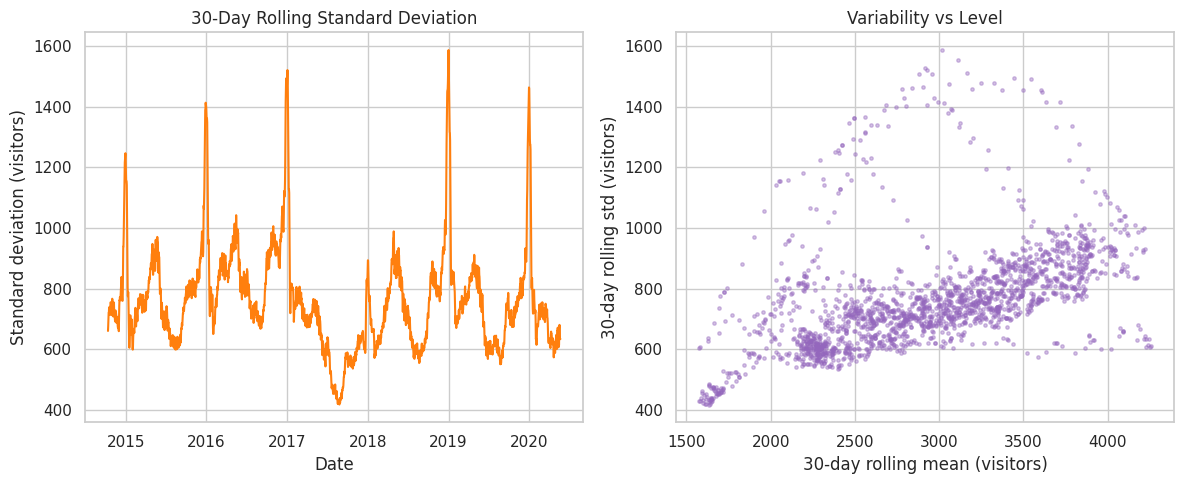

Correlation between level and variability: 0.49


In [18]:
rolling_std_30 = series.rolling(window=30).std()
rolling_mean_30 = series.rolling(window=30).mean()

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
axes[0].plot(rolling_std_30, color="tab:orange")
axes[0].set_title("30-Day Rolling Standard Deviation")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Standard deviation (visitors)")

axes[1].scatter(rolling_mean_30, rolling_std_30, s=6, alpha=0.4, color="tab:purple")
axes[1].set_title("Variability vs Level")
axes[1].set_xlabel("30-day rolling mean (visitors)")
axes[1].set_ylabel("30-day rolling std (visitors)")
finish_plot("03_rolling_std")

correlation = rolling_mean_30.corr(rolling_std_30)
print(f"Correlation between level and variability: {correlation:.2f}")

### Interpretation

- The left plot shows how variability changes over time. Part of the variability **is** the weekly cycle itself (weekday vs weekend differences are inside every 30-day window).
- The right plot and the printed correlation test whether **higher traffic comes with higher variability**. A strong positive correlation suggests a **multiplicative** pattern (the weekly swing grows with the level), and that a log transformation or a multiplicative seasonal model could help. We keep the additive models here for clarity, and mention a log transform as a possible improvement.

### 6.4 Distribution

**Concept:** A histogram (with a KDE curve) shows how the values are spread, ignoring time.

**Why:** It reveals skewness, multiple modes and outliers.

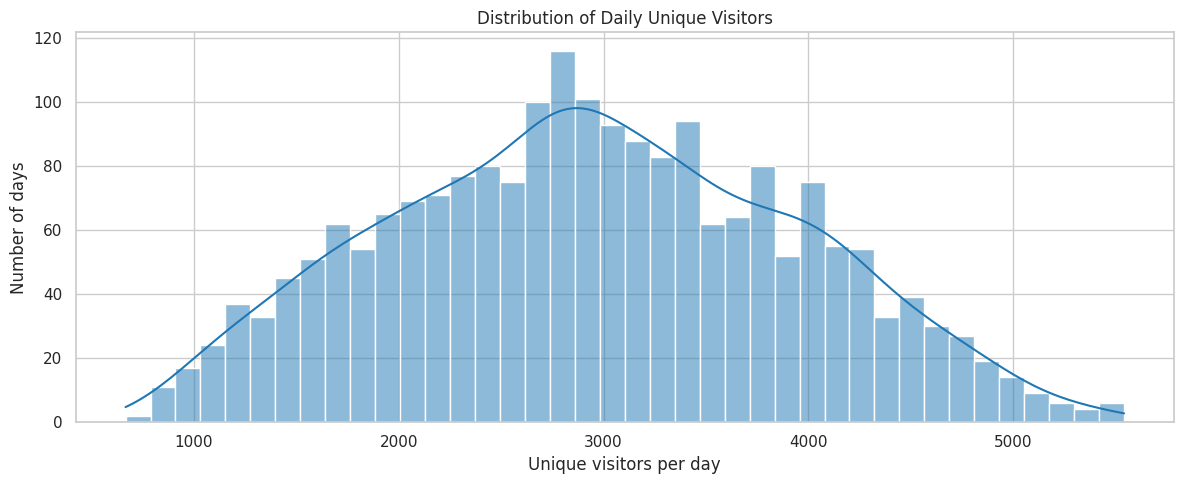

Mean: 2,948 | Median: 2,916 | Std: 991 | Skewness: 0.08


In [19]:
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.histplot(series, bins=40, kde=True, color="tab:blue", ax=ax)
ax.set_title("Distribution of Daily Unique Visitors")
ax.set_xlabel("Unique visitors per day")
ax.set_ylabel("Number of days")
finish_plot("04_distribution")

print(f"Mean: {series.mean():,.0f} | Median: {series.median():,.0f} | "
      f"Std: {series.std():,.0f} | Skewness: {series.skew():.2f}")

### Interpretation

Counts are bounded below by zero and often **right-skewed**: most days are ordinary and a few days are very busy. If the histogram has **more than one bump**, it often reflects different regimes, for example weekday vs weekend traffic or different eras of the site. The mean being above the median confirms right skew.

### 6.5 Visitor Types

**Concept:** The target (unique visitors) is the sum of **first-time** and **returning** visitors. Looking at both shows *what kind* of traffic drives the movements.

**Why:** If one component drives most of the changes, forecasts and business decisions should focus on that component.

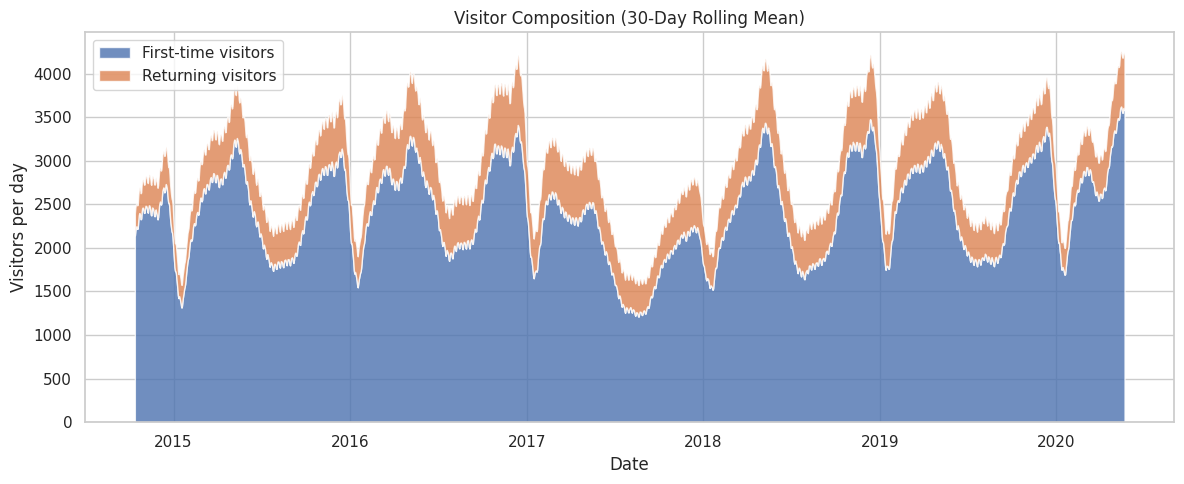

Share of first-time visitors over the training period: 82.5%


In [20]:
visitor_types = train_df[["first_time_visits", "returning_visits"]].rolling(window=30).mean().dropna()

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.stackplot(
    visitor_types.index,
    visitor_types["first_time_visits"],
    visitor_types["returning_visits"],
    labels=["First-time visitors", "Returning visitors"],
    alpha=0.8,
)
ax.set_title("Visitor Composition (30-Day Rolling Mean)")
ax.set_xlabel("Date")
ax.set_ylabel("Visitors per day")
ax.legend(loc="upper left")
finish_plot("05_visitor_types")

share_first_time = (train_df["first_time_visits"].sum() / train_df["unique_visits"].sum()) * 100
print(f"Share of first-time visitors over the training period: {share_first_time:.1f}%")

### Interpretation

The stacked areas show how the two groups add up to the total. If the first-time layer moves a lot while the returning layer is steadier, then traffic growth is mostly driven by *new* people finding the site (for example through search), whereas a stable returning layer reflects regular users such as students. The printed share summarises this for the whole training period.

## 7. Time-Based Patterns

**Concept:** Grouping observations by calendar components (weekday, month, year) shows how the target behaves at different points in the calendar.

**Why:** It turns visual impressions of seasonality into concrete numbers you can explain.

**Which patterns make sense here?** Website traffic from people is expected to have a **weekday effect** (the dataset author mentions day-of-week effects) and possibly a **time-of-year effect** (for a teaching site, linked to academic calendars). We investigate weekday, month, year and weekend vs weekday.

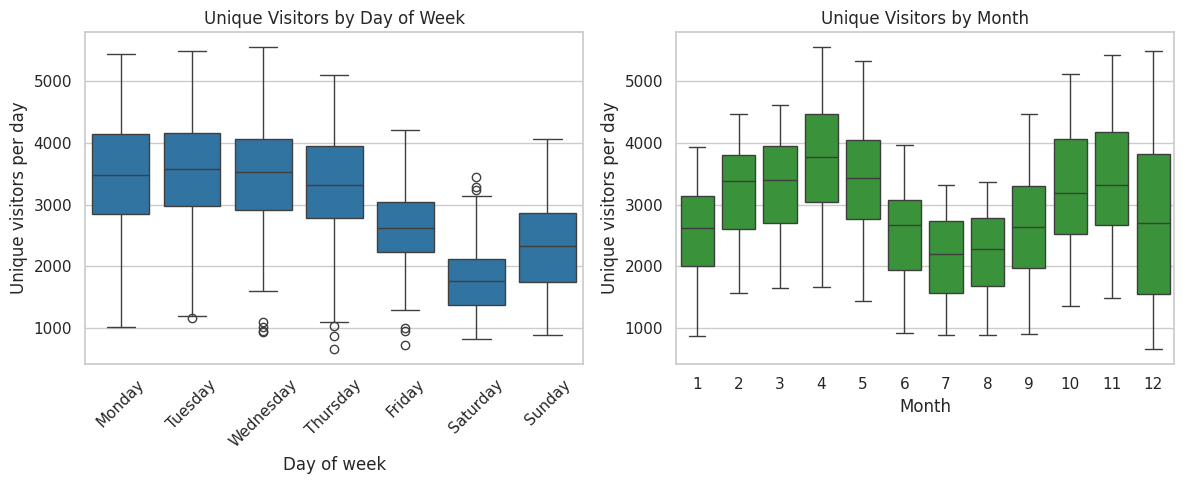

Average unique visitors by weekday:
weekday
Monday       3471.0
Tuesday      3555.0
Wednesday    3518.0
Thursday     3334.0
Friday       2641.0
Saturday     1775.0
Sunday       2336.0


In [21]:
calendar = pd.DataFrame({"unique_visits": series})
calendar["weekday"] = pd.Categorical(series.index.day_name(), categories=WEEKDAY_ORDER, ordered=True)
calendar["month"] = series.index.month
calendar["year"] = series.index.year
calendar["is_weekend"] = series.index.dayofweek >= 5

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
sns.boxplot(data=calendar, x="weekday", y="unique_visits", color="tab:blue", ax=axes[0])
axes[0].set_title("Unique Visitors by Day of Week")
axes[0].set_xlabel("Day of week")
axes[0].set_ylabel("Unique visitors per day")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=calendar, x="month", y="unique_visits", color="tab:green", ax=axes[1])
axes[1].set_title("Unique Visitors by Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Unique visitors per day")
finish_plot("06_weekday_and_month")

weekday_mean = calendar.groupby("weekday", observed=True)["unique_visits"].mean()
print("Average unique visitors by weekday:")
print(weekday_mean.round(0).to_string())

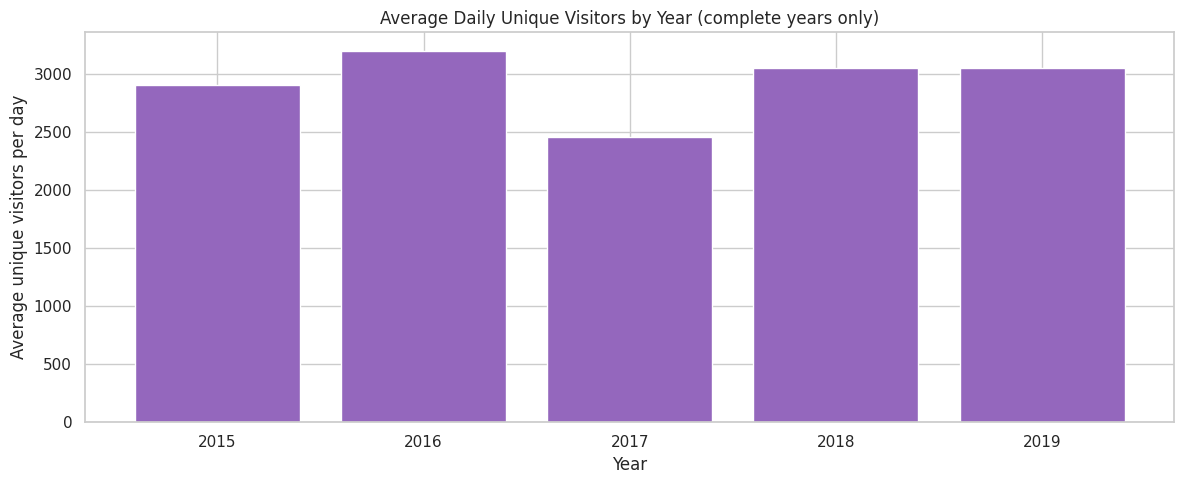

Weekday average : 3,304
Weekend average : 2,056
Weekend vs weekday difference: -37.8%


In [22]:
# Only complete calendar years for the yearly comparison
days_per_year = calendar.groupby("year").size()
complete_years = days_per_year[days_per_year >= 365].index
yearly_mean = calendar[calendar["year"].isin(complete_years)].groupby("year")["unique_visits"].mean()

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.bar(yearly_mean.index.astype(str), yearly_mean.values, color="tab:purple")
ax.set_title("Average Daily Unique Visitors by Year (complete years only)")
ax.set_xlabel("Year")
ax.set_ylabel("Average unique visitors per day")
finish_plot("07_yearly_mean")

weekend_mean = calendar.loc[calendar["is_weekend"], "unique_visits"].mean()
weekday_only_mean = calendar.loc[~calendar["is_weekend"], "unique_visits"].mean()
print(f"Weekday average : {weekday_only_mean:,.0f}")
print(f"Weekend average : {weekend_mean:,.0f}")
print(f"Weekend vs weekday difference: {(weekend_mean / weekday_only_mean - 1) * 100:+.1f}%")

### Interpretation

- **Day of week:** compare the boxes. Differences *between* weekdays that are large relative to the spread *within* a weekday indicate a strong, predictable weekly pattern. This is the single most useful feature for forecasting this series.
- **Month:** differences between months suggest a time-of-year effect. Note that daily data inside each month still contains the weekday effect, so month boxes are wide.
- **Year:** yearly averages show whether the overall level rose or fell over the years, which indicates a **trend** that models must handle. Only complete years are compared to avoid misleading partial-year averages.
- **Weekend vs weekday:** the printed percentage quantifies the weekday effect. It also shows what a model without weekly seasonality would get wrong on every weekend.

## 8. Resampling

**Concept:** **Resampling** changes the frequency of a time series, for example daily → weekly or monthly, by aggregating the observations in each new period.

**Why:** Lower frequencies reduce noise and highlight long-term structure. Different stakeholders also need different granularity.

**When is aggregation appropriate?** The aggregation function must match the meaning of the variable:

- Visit counts are **additive**: weekly **totals** (sum) are meaningful.
- For comparing levels across periods of different length we use the **mean daily** value.
- Incomplete periods (a partial first or last week or month) must be excluded, otherwise they produce misleading values.

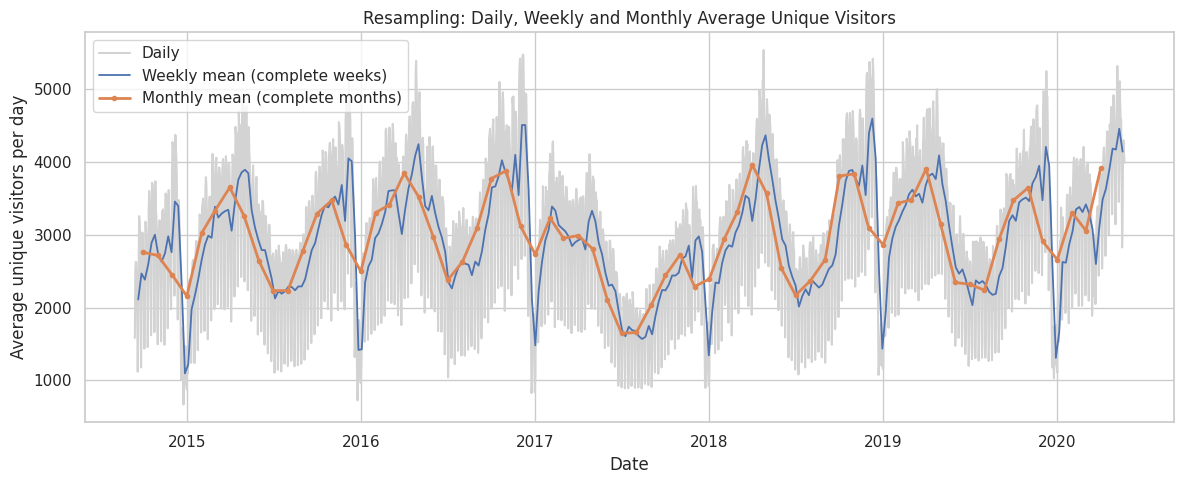

Daily observations : 2077
Weekly observations: 296
Monthly observations: 67

Weekly totals (sum of daily counts), first rows:


,weekly_total_unique_visits
date,
2014-09-21,14775
2014-09-28,17282
2014-10-05,16689
2014-10-12,18150
2014-10-19,20231


In [23]:
# Weeks end on Sunday ("W-SUN"); keep only complete weeks of 7 observed days
weekly_counts = series.resample("W-SUN").count()
weekly_total = series.resample("W-SUN").sum()[weekly_counts == 7]
weekly_mean = (weekly_total / 7)

# Months: keep only complete months
monthly_mean = series.resample("MS").mean()
days_observed = series.resample("MS").count()
is_complete_month = days_observed.to_numpy() == monthly_mean.index.days_in_month.to_numpy()
monthly_mean = monthly_mean[is_complete_month]

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(series, color="lightgrey", label="Daily")
ax.plot(weekly_mean, linewidth=1.3, label="Weekly mean (complete weeks)")
ax.plot(monthly_mean, linewidth=2, marker="o", markersize=3, label="Monthly mean (complete months)")
ax.set_title("Resampling: Daily, Weekly and Monthly Average Unique Visitors")
ax.set_xlabel("Date")
ax.set_ylabel("Average unique visitors per day")
ax.legend()
finish_plot("08_resampling")

print(f"Daily observations : {len(series)}")
print(f"Weekly observations: {len(weekly_mean)}")
print(f"Monthly observations: {len(monthly_mean)}")
print("\nWeekly totals (sum of daily counts), first rows:")
display(weekly_total.head().to_frame("weekly_total_unique_visits"))

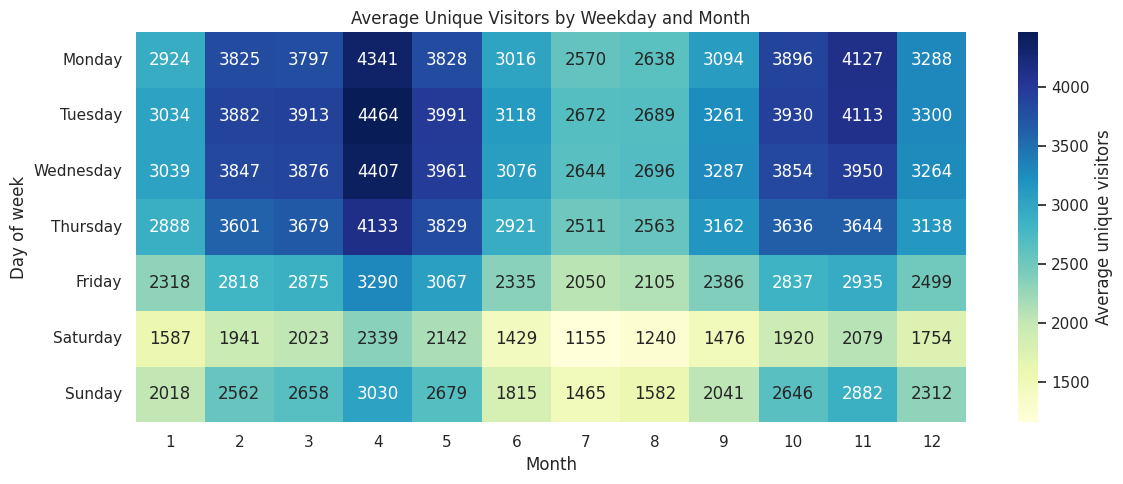

In [24]:
heatmap_data = calendar.pivot_table(
    index="weekday", columns="month", values="unique_visits", aggfunc="mean", observed=True
).reindex(WEEKDAY_ORDER).astype(float)

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap="YlGnBu",
            cbar_kws={"label": "Average unique visitors"}, ax=ax)
ax.set_title("Average Unique Visitors by Weekday and Month")
ax.set_xlabel("Month")
ax.set_ylabel("Day of week")
finish_plot("09_weekday_month_heatmap")

monthly_climatology = monthly_mean.groupby(monthly_mean.index.month).mean()

### Interpretation

- Weekly and monthly means remove the weekday noise and make slower movements (growth, decline, time-of-year effects) much clearer. The monthly series has only about 60 points, which is too few to fit seasonal models reliably, so **we model the daily series** and use resampling to understand it.
- The **heatmap** combines both effects. Rows (weekdays) that are consistently lighter or darker across columns show a stable weekly pattern. Columns (months) that are darker overall show busier periods of the year. If the colour pattern across weekdays differs between months, the weekly pattern itself changes during the year.

## 9. Decomposition

**Concept:** Decomposition splits a series into **trend**, **seasonal** and **residual** components. Here we have *two* seasonal scales, so we decompose twice:

1. **Weekly seasonality** on the daily data (`period = 7`).
2. **Yearly seasonality** on the weekly-average data (`period = 52`), where a yearly cycle is much easier to see than in noisy daily data.

An **additive** model assumes `observed = trend + seasonal + residual`. We use additive models for clarity. If the earlier variability-vs-level check showed a strong relationship, a multiplicative or log-scale model would also be reasonable (we test a log-scale model later).

**Why:** Decomposition tells us *how much* of the variation is predictable seasonality, and at which scale, which guides model choice.

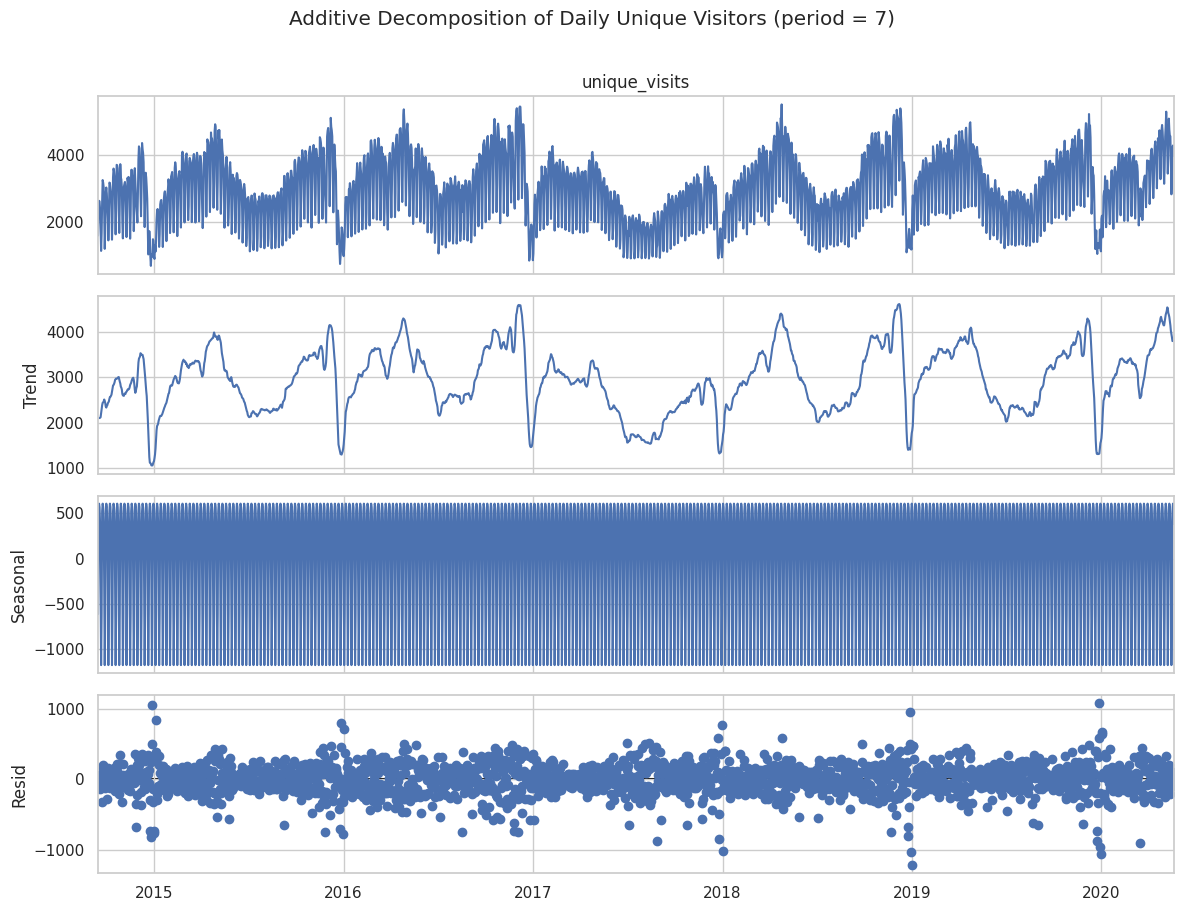

Weekly seasonal strength : 0.90
Trend strength           : 0.92


In [25]:
def seasonal_trend_strength(decomposition):
    """Strength of seasonality and trend (0 = none, 1 = very strong), after Hyndman & Athanasopoulos."""
    residual = decomposition.resid.dropna()
    seasonal_part = decomposition.seasonal.loc[residual.index]
    trend_part = decomposition.trend.loc[residual.index]
    seasonal_strength = max(0.0, 1 - residual.var() / (residual + seasonal_part).var())
    trend_strength = max(0.0, 1 - residual.var() / (residual + trend_part).var())
    return seasonal_strength, trend_strength


decomposition_weekly = seasonal_decompose(series, model="additive", period=WEEKLY_PERIOD)
fig = decomposition_weekly.plot()
fig.set_size_inches(12, 9)
fig.suptitle("Additive Decomposition of Daily Unique Visitors (period = 7)", y=1.01)
finish_plot("10_decomposition_weekly")

weekly_seasonal_strength, trend_strength = seasonal_trend_strength(decomposition_weekly)
print(f"Weekly seasonal strength : {weekly_seasonal_strength:.2f}")
print(f"Trend strength           : {trend_strength:.2f}")

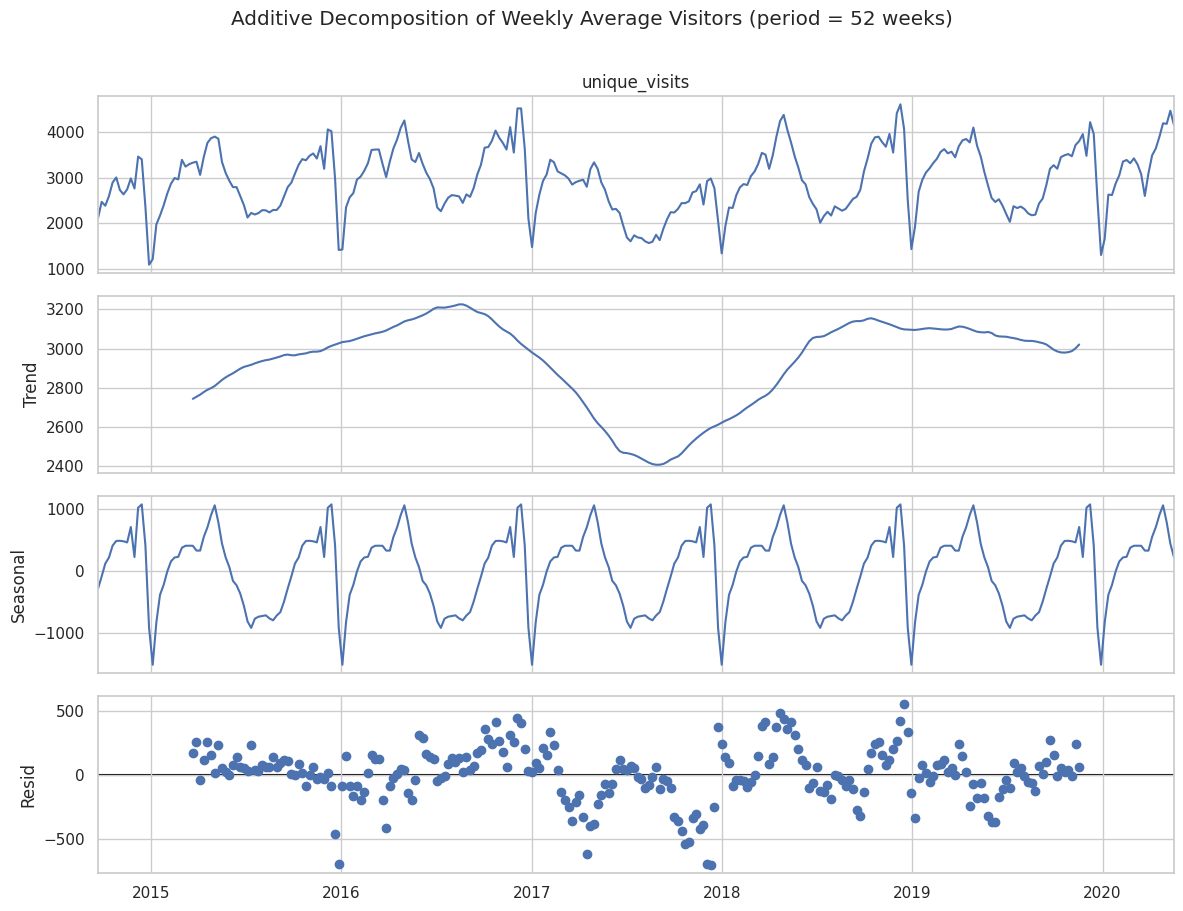

Yearly seasonal strength (weekly data): 0.89


In [26]:
decomposition_yearly = seasonal_decompose(weekly_mean, model="additive", period=52)
fig = decomposition_yearly.plot()
fig.set_size_inches(12, 9)
fig.suptitle("Additive Decomposition of Weekly Average Visitors (period = 52 weeks)", y=1.01)
finish_plot("11_decomposition_yearly")

yearly_seasonal_strength, _ = seasonal_trend_strength(decomposition_yearly)
print(f"Yearly seasonal strength (weekly data): {yearly_seasonal_strength:.2f}")

### Interpretation

- **Weekly decomposition:** the seasonal panel shows the repeating 7-day shape (the weekday profile). A weekly strength close to 1 means most of the short-term variation is this predictable cycle. The trend panel is the 7-day centred average, so it follows the slower level.
- **Trend:** the trend strength compares trend variation with the remaining noise. A high value means the level moves a lot over time, which matters for ARIMA-type models (they handle this through differencing).
- **Yearly decomposition:** the yearly seasonal pattern repeats once per year. It needs a minimum of two full years, and the estimate is based on only about five or six repetitions, so it is less reliable than the weekly pattern. The strength value tells us how much of the weekly-average movement is a repeating time-of-year effect, as opposed to trend and irregular changes.
- **Residuals** are the unexplained part. Large residual spikes indicate unusual days that no seasonal model would predict.

## 10. Stationarity

**Concept:** A time series is **(weakly) stationary** if its mean, variance and autocorrelation structure do not depend on *when* you look.

**Why it matters:** ARIMA-type models are built for stationary data (after differencing). A series with trend or seasonality has a changing mean.

### The Augmented Dickey-Fuller (ADF) test

- **Null hypothesis (H0):** the series has a **unit root** (non-stationary).
- **Alternative hypothesis (H1):** no unit root (stationary).
- **p-value:** the probability of seeing a result at least this extreme *if H0 were true*. `p < 0.05` → reject H0 → evidence of stationarity. `p ≥ 0.05` → fail to reject H0.
- The ADF statistic must be *more negative* than the critical value to reject H0.

> **Caveat:** ADF tests for a **stochastic trend** (unit root). It has limited power against strong **deterministic seasonality**, so we combine it with plots, the seasonal-strength measure and ACF.

In [27]:
def adf_p_value(data):
    """Return only the ADF p-value."""
    return adfuller(data.dropna(), autolag="AIC")[1]


def run_adf_test(data, label):
    """Run the ADF test, print a readable report and return the p-value."""
    statistic, p_value, used_lags, n_obs, critical_values, _ = adfuller(data.dropna(), autolag="AIC")

    print(f"ADF test: {label}")
    print(f"  ADF statistic : {statistic:.4f}")
    print(f"  p-value       : {p_value:.4f}")
    print(f"  Lags used     : {used_lags}")
    print(f"  Observations  : {n_obs}")
    print("  Critical values:")
    for level, value in critical_values.items():
        print(f"    {level:>3}: {value:.4f}")

    if p_value < ALPHA:
        print(f"  -> p < {ALPHA}: reject H0. Evidence that the series is STATIONARY.\n")
    else:
        print(f"  -> p >= {ALPHA}: fail to reject H0. The series is treated as NON-STATIONARY.\n")
    return p_value


adf_p_original = run_adf_test(series, "daily unique visitors (original)")

ADF test: daily unique visitors (original)
  ADF statistic : -4.4046
  p-value       : 0.0003
  Lags used     : 26
  Observations  : 2050
  Critical values:
     1%: -3.4335
     5%: -2.8630
    10%: -2.5675
  -> p < 0.05: reject H0. Evidence that the series is STATIONARY.



### Interpretation

Read the report in three steps: (1) compare the **ADF statistic** with the 5% critical value, (2) check the **p-value** against 0.05, (3) read the printed conclusion.

Even a series that passes the ADF test is **not stationary in the strict sense** if it has a weekly cycle: its mean changes predictably with the weekday. The test addresses *random-walk-like* drift, while the *deterministic weekly seasonality* still needs to be handled by the model, either with **seasonal differencing** or explicit seasonal terms.

## 11. Differencing

**Concept:** There are two kinds of differencing, and this dataset needs us to think about both:

- **Regular (first-order) differencing:** `y(t) − y(t−1)` removes slow level changes (trend / unit root).
- **Seasonal differencing (lag 7):** `y(t) − y(t−7)` removes a repeating weekly pattern by comparing each day with the same weekday a week earlier.

**Why:** Differencing makes a series closer to stationary. But **over-differencing** adds noise, so each step must be justified and tested.

**Rules decided before looking at model scores**

- Non-seasonal ARIMA: `d = 1` only if the ADF test on the original series fails to reject a unit root.
- SARIMA: seasonal differencing `D = 1` if the weekly seasonal strength exceeds **0.64**, a threshold used by common automatic-differencing rules; then `d` is decided by an ADF test on the seasonally differenced series.

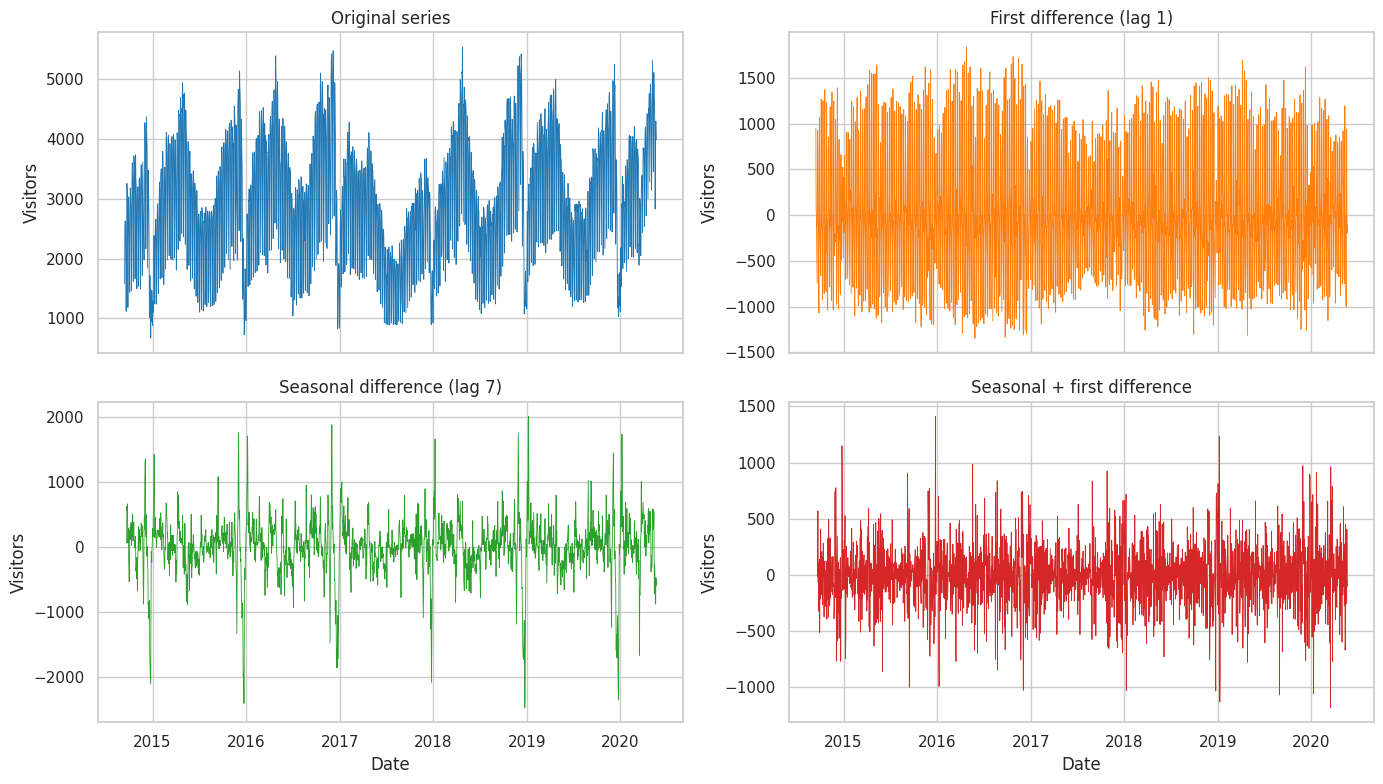

ADF test: first difference
  ADF statistic : -11.9972
  p-value       : 0.0000
  Lags used     : 26
  Observations  : 2049
  Critical values:
     1%: -3.4335
     5%: -2.8630
    10%: -2.5675
  -> p < 0.05: reject H0. Evidence that the series is STATIONARY.

ADF test: seasonal difference (lag 7)
  ADF statistic : -9.8415
  p-value       : 0.0000
  Lags used     : 21
  Observations  : 2048
  Critical values:
     1%: -3.4335
     5%: -2.8630
    10%: -2.5675
  -> p < 0.05: reject H0. Evidence that the series is STATIONARY.

ADF test: seasonal + first difference
  ADF statistic : -15.4781
  p-value       : 0.0000
  Lags used     : 24
  Observations  : 2044
  Critical values:
     1%: -3.4336
     5%: -2.8630
    10%: -2.5675
  -> p < 0.05: reject H0. Evidence that the series is STATIONARY.



In [28]:
SEASONAL_STRENGTH_THRESHOLD = 0.64

series_diff = series.diff().dropna()
series_seasonal_diff = series.diff(WEEKLY_PERIOD).dropna()
series_both_diff = series.diff(WEEKLY_PERIOD).diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
panels = [
    (series, "Original series", "tab:blue"),
    (series_diff, "First difference (lag 1)", "tab:orange"),
    (series_seasonal_diff, "Seasonal difference (lag 7)", "tab:green"),
    (series_both_diff, "Seasonal + first difference", "tab:red"),
]
for ax, (data, title, color) in zip(axes.ravel(), panels):
    ax.plot(data, color=color, linewidth=0.6)
    ax.set_title(title)
    ax.set_ylabel("Visitors")
for ax in axes[1]:
    ax.set_xlabel("Date")
finish_plot("12_differencing")

adf_p_diff = run_adf_test(series_diff, "first difference")
adf_p_seasonal = run_adf_test(series_seasonal_diff, "seasonal difference (lag 7)")
adf_p_both = run_adf_test(series_both_diff, "seasonal + first difference")

In [29]:
# Differencing orders, chosen by the rules stated above
d_order = 0 if adf_p_original < ALPHA else 1                    # plain ARIMA
D_seasonal = 1 if weekly_seasonal_strength > SEASONAL_STRENGTH_THRESHOLD else 0

sarima_base = series.diff(WEEKLY_PERIOD).dropna() if D_seasonal else series
d_sarima = 0 if adf_p_value(sarima_base) < ALPHA else 1          # SARIMA regular difference

print(f"Plain ARIMA        : d = {d_order}")
print(f"SARIMA             : d = {d_sarima}, D = {D_seasonal} (seasonal period {WEEKLY_PERIOD})")

Plain ARIMA        : d = 0
SARIMA             : d = 0, D = 1 (seasonal period 7)


### Interpretation

- The **first difference** removes slow level changes but leaves the weekly zig-zag, since weekday differences between neighbouring days remain.
- The **seasonal difference (lag 7)** compares each day with the same weekday last week, which removes the weekday profile and any slow drift smaller than a week. It usually produces a series that fluctuates around zero without a visible weekly pattern.
- Applying **both** can remove too much information; the printed rules decide the minimum needed. If `D = 1` and `d = 0`, the seasonal difference alone was enough.
- The ADF p-values show which transformed versions are stationary. The key practical outcome is the pair `(d, D)` printed above.

## 12. ACF and PACF

**Concept**

- **Lag:** a time shift. Lag 1 compares each day with the previous day; lag 7 with the same weekday a week earlier.
- **Autocorrelation (ACF):** the correlation between the series and its lagged copy, including indirect effects.
- **Partial autocorrelation (PACF):** the correlation at lag *k* after removing the effect of the shorter lags.

**Why:** ACF/PACF patterns suggest model structure.

| Pattern | Suggests |
|---|---|
| Spikes at lags 7, 14, 21, … that decay slowly | weekly seasonality (seasonal differencing needed) |
| After differencing: ACF cuts off after lag *q*, PACF decays | MA(*q*) |
| After differencing: PACF cuts off after lag *p*, ACF decays | AR(*p*) |
| Significant spike at lag 7 only in the ACF | seasonal MA term (Q = 1) |
| Significant spike at lag 7 only in the PACF | seasonal AR term (P = 1) |

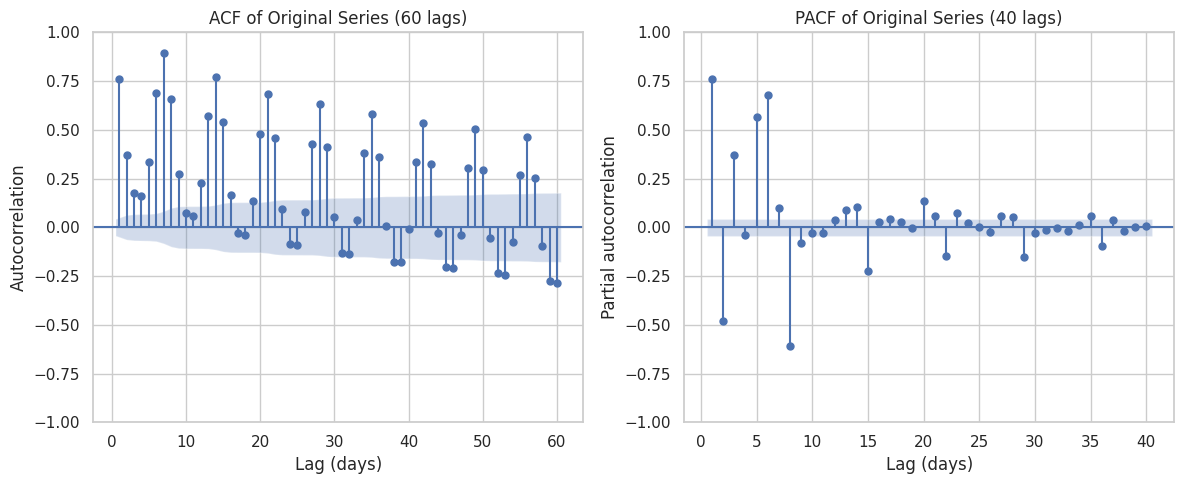

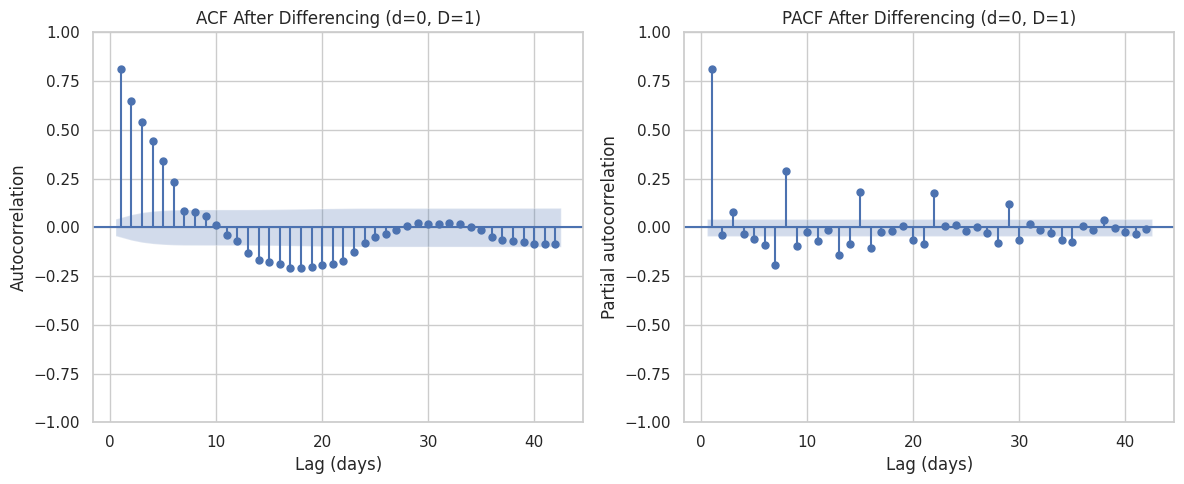

In [30]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
plot_acf(series, lags=60, ax=axes[0], zero=False)
axes[0].set_title("ACF of Original Series (60 lags)")
axes[0].set_xlabel("Lag (days)")
axes[0].set_ylabel("Autocorrelation")
plot_pacf(series, lags=40, ax=axes[1], zero=False, method="ywm")
axes[1].set_title("PACF of Original Series (40 lags)")
axes[1].set_xlabel("Lag (days)")
axes[1].set_ylabel("Partial autocorrelation")
finish_plot("13_acf_pacf_original")

# The series that the SARIMA model effectively works with, after its differencing
sarima_input = series
if D_seasonal:
    sarima_input = sarima_input.diff(WEEKLY_PERIOD)
if d_sarima:
    sarima_input = sarima_input.diff()
sarima_input = sarima_input.dropna()

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
plot_acf(sarima_input, lags=42, ax=axes[0], zero=False)
axes[0].set_title(f"ACF After Differencing (d={d_sarima}, D={D_seasonal})")
axes[0].set_xlabel("Lag (days)")
axes[0].set_ylabel("Autocorrelation")
plot_pacf(sarima_input, lags=42, ax=axes[1], zero=False, method="ywm")
axes[1].set_title(f"PACF After Differencing (d={d_sarima}, D={D_seasonal})")
axes[1].set_xlabel("Lag (days)")
axes[1].set_ylabel("Partial autocorrelation")
finish_plot("14_acf_pacf_differenced")

### Interpretation

- **Original series:** a slow decay in the ACF with a **repeating bump every 7 lags** is the signature of weekly seasonality. The PACF typically shows large spikes at the first lags and at lag 7.
- **After differencing:** the weekly bumps should largely disappear. Remaining spikes near lags 1-2 suggest the short-term AR/MA terms, and a remaining spike at lag 7 (and 14) suggests a seasonal AR or MA term.
- Shaded bands are approximate 95% limits: spikes outside them are statistically meaningful.
- We therefore keep the order search **small**: non-seasonal orders up to 2, and a seasonal MA term (Q = 1), with or without a seasonal AR term (P = 1). The final orders are chosen by **AIC on training data only**, rewarding fit and penalising complexity, far more defensible than testing hundreds of combinations.

## 13. Train/Test Split

**Concept:** The last 90 days are held out as the **test set**; everything before is the **training set** (created in section 5).

**Why a chronological split?** Forecasting means predicting the *future* from the *past*. A random split would put future days into the training set, allowing the model to "peek" at tomorrow to predict yesterday. Neighbouring days are strongly correlated, so a random split would also make the test set an almost-copy of the training set, a form of **data leakage** that produces unrealistically good scores.

Train: 2014-09-14 to 2020-05-21 (2077 days)
Test : 2020-05-22 to 2020-08-19 (90 days)


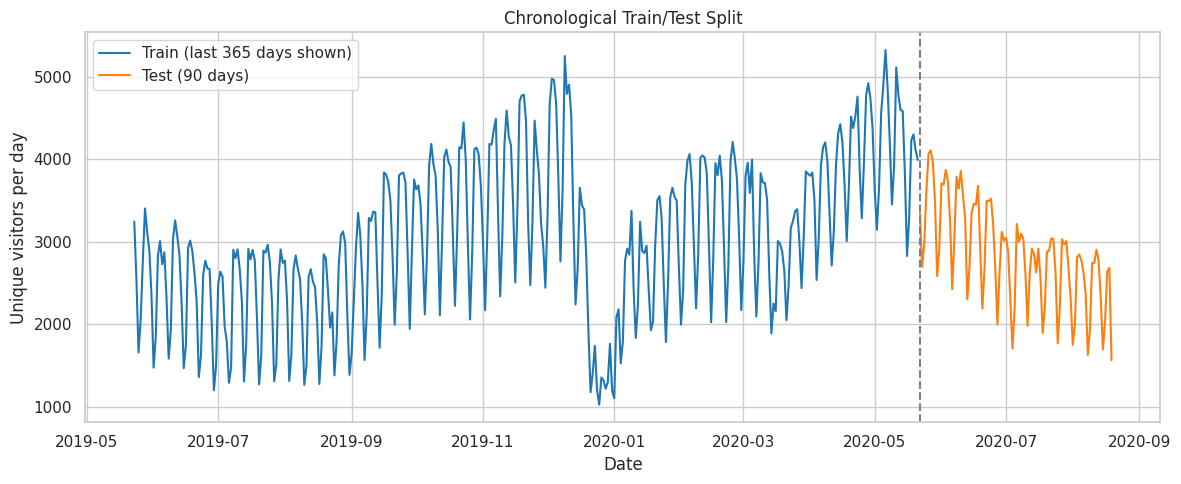

In [31]:
print(f"Train: {train.index.min().date()} to {train.index.max().date()} ({len(train)} days)")
print(f"Test : {test.index.min().date()} to {test.index.max().date()} ({len(test)} days)")

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(train.iloc[-365:], label="Train (last 365 days shown)", color="tab:blue")
ax.plot(test, label="Test (90 days)", color="tab:orange")
ax.axvline(test.index[0], color="grey", linestyle="--")
ax.set_title("Chronological Train/Test Split")
ax.set_xlabel("Date")
ax.set_ylabel("Unique visitors per day")
ax.legend()
finish_plot("15_train_test_split")

### Interpretation

- The dashed line separates the **past (train)** from the **future (test)**. All parameter selection and fitting for the one-shot evaluation use only the training data.
- 90 days is about **13 weekly cycles**, so the test set contains enough full weeks to judge weekly seasonality, but it covers only **one part of the year**. Time-of-year effects are therefore only partly tested.
- The rolling-origin evaluation in section 16 re-uses this same 90-day window but forecasts in shorter steps with refitting, which gives more reliable evidence.

## 14. Baseline Models and Evaluation Metrics

**Concept:** A **baseline** is the simplest sensible forecast. We use:

1. **Naive:** the last observed value repeated.
2. **Seasonal naive (7 days):** each future day equals the same weekday in the most recent observed week.
3. **Seasonal mean (8 weeks):** each future day equals the average of the same weekday over the last 8 weeks.
4. **Moving average (7 days):** the mean of the last 7 days repeated.

**Why:** A sophisticated model is only worthwhile if it beats these simple rules. For this dataset, the seasonal baselines are demanding competitors because the weekly pattern is so strong.

### Evaluation metrics

- **MAE** – average absolute error in visitors. Easy to interpret.
- **RMSE** – penalises large errors more than MAE.
- **MAPE** – percentage error. Appropriate here because visitor counts are positive and on a ratio scale.
- **Bias** – average of `actual − forecast`; positive means the model under-forecasts on average.

In [32]:
def evaluate_forecast(actual, predicted):
    """Return MAE, RMSE, MAPE (%) and bias for aligned actual and predicted values."""
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    non_zero = actual != 0
    return {
        "MAE": float(mean_absolute_error(actual, predicted)),
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "MAPE (%)": float(np.mean(np.abs((actual[non_zero] - predicted[non_zero]) / actual[non_zero])) * 100),
        "Bias": float(np.mean(actual - predicted)),
    }


def forecast_naive(history, index):
    """Repeat the last observed value."""
    return pd.DataFrame({"forecast": history.iloc[-1]}, index=index)


def _same_weekday_lookup_dates(history, index, extra_cycles=0, period_days=WEEKLY_PERIOD):
    """For each forecast date, the date `period_days` multiples earlier that is already observed."""
    days_ahead = (index - history.index[-1]).days.to_numpy()
    cycles_back = np.ceil(days_ahead / period_days).astype(int) + extra_cycles
    return index - pd.to_timedelta(cycles_back * period_days, unit="D")


def forecast_seasonal_naive(history, index):
    """Use the most recent observed value for the same weekday."""
    values = history.reindex(_same_weekday_lookup_dates(history, index)).to_numpy()
    return pd.DataFrame({"forecast": values}, index=index)


def forecast_seasonal_mean(history, index, n_cycles=8):
    """Average the most recent `n_cycles` observed values for the same weekday."""
    lookups = [
        history.reindex(_same_weekday_lookup_dates(history, index, extra_cycles=k)).to_numpy()
        for k in range(n_cycles)
    ]
    return pd.DataFrame({"forecast": np.nanmean(np.vstack(lookups), axis=0)}, index=index)


def forecast_moving_average(history, index, window=7):
    """Repeat the mean of the last `window` observations."""
    return pd.DataFrame({"forecast": history.iloc[-window:].mean()}, index=index)


naive_scores = evaluate_forecast(test, forecast_naive(train, test.index)["forecast"])
seasonal_scores = evaluate_forecast(test, forecast_seasonal_naive(train, test.index)["forecast"])
print("Naive             :", {k: round(v, 2) for k, v in naive_scores.items()})
print("Seasonal naive (7):", {k: round(v, 2) for k, v in seasonal_scores.items()})

Naive             : {'MAE': 1145.62, 'RMSE': 1290.59, 'MAPE (%)': 47.4, 'Bias': -1141.31}
Seasonal naive (7): {'MAE': 945.44, 'RMSE': 1049.1, 'MAPE (%)': 36.93, 'Bias': -945.44}


### Interpretation

The **naive** forecast is a flat line, so it cannot represent the weekday pattern at all: every weekend is over-forecast and every busy weekday under-forecast. The **seasonal naive** forecast repeats last week's shape, so it already captures the weekday profile. Any advanced model must beat the seasonal baselines to justify its complexity.

## 15. Forecasting Models

We compare **13 models**, each fitted using only data available before the forecast starts.

| # | Model | Family | Idea |
|---|---|---|---|
| 1 | **Naive** | baseline | last value repeated |
| 2 | **Seasonal Naive (7d)** | baseline | same weekday last week |
| 3 | **Seasonal Mean (8 weeks)** | baseline | same weekday, averaged over 8 weeks |
| 4 | **Moving Average (7d)** | smoothing | level of the last 7 days |
| 5 | **ARIMA** | classical | no seasonal terms |
| 6 | **SARIMA (weekly)** | classical seasonal | ARIMA with seasonal terms at lag 7 |
| 7 | **SARIMA (log scale)** | transformed | same SARIMA on `log(1 + visitors)`, back-transformed |
| 8 | **SARIMAX + weekday dummies + yearly Fourier** | regression with ARIMA errors | explicit weekday and yearly seasonal regressors |
| 9 | **Holt-Winters** | exponential smoothing | damped additive trend, additive weekly seasonality |
| 10 | **STL + ARIMA** | decomposition | remove weekly pattern with STL, forecast the rest with ARIMA |
| 11 | **Theta** | classical | seasonally adjusted Theta method |
| 12 | **Random Forest (lags)** | machine learning | lags + calendar features, recursive forecasting |
| 13 | **Gradient Boosting (lags)** | machine learning | same features, boosted trees |

### Why a true SARIMA here?

Weekly seasonality has period 7, so `SARIMA(p,d,q)(P,D,Q)[7]` is practical, unlike a 365-day season in daily data. The yearly effect is handled with **Fourier terms** in model 8.

### Why a log-scale model?

If the weekly swing grows with the level of traffic, a log transform makes the pattern more additive and stabilises variance. Back-transforming a log-scale forecast gives roughly the **median**, not the mean, so a small downward bias is possible.

### How the parameters are chosen

- Differencing orders follow the rules in section 11.
- `p`, `q` and the seasonal terms are searched over **small grids** and ranked by **AIC on the training data only**.
- **Machine-learning models:** fixed, moderate hyperparameters, with no tuning on the test set.

> **Note:** AIC is only comparable between models fitted to the same series with the same differencing, so we only compare orders *within* a model family. Families are compared by forecast error.
> The search cells below may take a few minutes.

In [33]:
def make_fourier_terms(index, origin, period=365.25, n_harmonics=2):
    """Build sine/cosine columns that represent a smooth yearly cycle."""
    days_since_origin = (index - origin).days.to_numpy()
    terms = {}
    for k in range(1, n_harmonics + 1):
        angle = 2 * np.pi * k * days_since_origin / period
        terms[f"sin_{k}"] = np.sin(angle)
        terms[f"cos_{k}"] = np.cos(angle)
    return pd.DataFrame(terms, index=index)


def make_calendar_features(index, origin, n_harmonics=2):
    """Yearly Fourier terms plus weekday dummies (Monday is the reference day)."""
    features = make_fourier_terms(index, origin, n_harmonics=n_harmonics)
    for weekday in range(1, 7):
        features[f"dow_{weekday}"] = (index.dayofweek == weekday).astype(float)
    return features


def fit_sarimax(history, order, seasonal_order=(0, 0, 0, 0), exog=None):
    """Fit a SARIMAX model; a constant is only included when nothing is differenced."""
    trend = "c" if order[1] + seasonal_order[1] == 0 else "n"
    model = SARIMAX(history, exog=exog, order=order, seasonal_order=seasonal_order, trend=trend)
    return model.fit(disp=False)


def make_order_grid(d, max_p=2, max_q=2):
    """All (p, d, q) combinations up to the given limits."""
    return [(p, d, q) for p in range(max_p + 1) for q in range(max_q + 1)]


def rank_by_aic(history, orders, seasonal_orders=((0, 0, 0, 0),), exog=None):
    """Fit every candidate and rank by AIC (lower is better)."""
    records = []
    for order in orders:
        for seasonal_order in seasonal_orders:
            try:
                fitted = fit_sarimax(history, order, seasonal_order, exog)
            except (ValueError, np.linalg.LinAlgError):
                continue
            records.append({"order": order, "seasonal_order": seasonal_order, "AIC": fitted.aic})
    return pd.DataFrame(records).sort_values("AIC").reset_index(drop=True)


FOURIER_ORIGIN = train.index[0]

### Model 5: ARIMA (no seasonality)

In [34]:
arima_search = rank_by_aic(train, make_order_grid(d_order))
display(arima_search[["order", "AIC"]])

arima_order = arima_search.loc[0, "order"]
print(f"Selected ARIMA order: {arima_order}")

,order,AIC
0,"(2, 0, 2)",31799.106338
1,"(1, 0, 2)",31831.258764
2,"(0, 0, 2)",31835.160874
3,"(1, 0, 1)",31920.171810
4,"(2, 0, 1)",31985.257743
5,"(2, 0, 0)",32214.874852
6,"(0, 0, 1)",32565.217697
7,"(1, 0, 0)",32766.007023
8,"(0, 0, 0)",34553.453787


Selected ARIMA order: (2, 0, 2)


### Models 6 and 7: SARIMA (weekly)

The seasonal part is `(P, D, Q, 7)`. `D` comes from section 11, and we try a seasonal MA term alone `(0, D, 1)` and together with a seasonal AR term `(1, D, 1)`, following the ACF/PACF guidance.

In [35]:
sarima_orders = make_order_grid(d_sarima, max_p=2, max_q=1)
sarima_seasonal_orders = [(0, D_seasonal, 1, WEEKLY_PERIOD), (1, D_seasonal, 1, WEEKLY_PERIOD)]

sarima_search = rank_by_aic(train, sarima_orders, sarima_seasonal_orders)
display(sarima_search)

sarima_order = sarima_search.loc[0, "order"]
sarima_seasonal_order = sarima_search.loc[0, "seasonal_order"]
print(f"Selected SARIMA: order {sarima_order}, seasonal order {sarima_seasonal_order}")

,order,seasonal_order,AIC
0,"(2, 0, 1)","(1, 1, 1, 7)",28287.913344
1,"(1, 0, 1)","(1, 1, 1, 7)",28297.189096
2,"(2, 0, 0)","(1, 1, 1, 7)",28298.995778
3,"(1, 0, 0)","(1, 1, 1, 7)",28300.856981
4,"(2, 0, 1)","(0, 1, 1, 7)",28407.333444
5,"(1, 0, 1)","(0, 1, 1, 7)",28419.245962
6,"(2, 0, 0)","(0, 1, 1, 7)",28422.867236
7,"(1, 0, 0)","(0, 1, 1, 7)",28429.382446
8,"(0, 0, 1)","(1, 1, 1, 7)",29595.625624
9,"(0, 0, 1)","(0, 1, 1, 7)",29793.300390


Selected SARIMA: order (2, 0, 1), seasonal order (1, 1, 1, 7)


### Model 8: SARIMAX with weekday dummies and yearly Fourier terms

The weekly pattern is represented by **weekday dummy variables** and the yearly cycle by **Fourier terms**, so the ARIMA part only has to model the remaining short-term dependence (`d = 0`). We choose the number of yearly harmonics `K` (1-3) by AIC.

In [36]:
regression_rows = []
for n_harmonics in (1, 2, 3):
    exog_train = make_calendar_features(train.index, FOURIER_ORIGIN, n_harmonics)
    best_row = rank_by_aic(train, make_order_grid(0, max_p=2, max_q=1), exog=exog_train).loc[0]
    regression_rows.append(
        {"harmonics (K)": n_harmonics, "best order": best_row["order"], "AIC": best_row["AIC"]}
    )

regression_search = pd.DataFrame(regression_rows).sort_values("AIC").reset_index(drop=True)
display(regression_search)

n_harmonics_selected = int(regression_search.loc[0, "harmonics (K)"])
regression_order = regression_search.loc[0, "best order"]
print(f"Selected: K = {n_harmonics_selected} yearly harmonics, ARIMA errors {regression_order}")

,harmonics (K),best order,AIC
0,2,"(1, 0, 0)",29220.638569
1,3,"(1, 0, 0)",29393.974863
2,1,"(2, 0, 0)",32393.430538


Selected: K = 2 yearly harmonics, ARIMA errors (1, 0, 0)


### Model 10: STL + ARIMA

STL (Seasonal-Trend decomposition using LOESS) removes the weekly pattern. The ARIMA order is chosen on the seasonally adjusted **training** series.

In [37]:
stl_result = STL(train, period=WEEKLY_PERIOD).fit()
seasonally_adjusted = train - stl_result.seasonal

d_stl = 0 if adf_p_value(seasonally_adjusted) < ALPHA else 1
stl_search = rank_by_aic(seasonally_adjusted, make_order_grid(d_stl))
display(stl_search[["order", "AIC"]])

stl_order = stl_search.loc[0, "order"]
print(f"Selected ARIMA order for the seasonally adjusted series: {stl_order}")

,order,AIC
0,"(2, 0, 2)",26997.082979
1,"(1, 0, 2)",26997.116953
2,"(2, 0, 1)",27005.362943
3,"(1, 0, 0)",27006.311376
4,"(1, 0, 1)",27008.114140
5,"(2, 0, 0)",27008.151419
6,"(0, 0, 2)",29431.013197
7,"(0, 0, 1)",31037.804596
8,"(0, 0, 0)",33265.797234


Selected ARIMA order for the seasonally adjusted series: (2, 0, 2)


In [38]:
def _forecast_with_intervals(fitted_model, index, exog=None, alpha=ALPHA):
    """Return point forecasts and prediction intervals as a DataFrame."""
    prediction = fitted_model.get_forecast(steps=len(index), exog=exog)
    intervals = prediction.conf_int(alpha=alpha)
    return pd.DataFrame(
        {
            "forecast": prediction.predicted_mean.to_numpy(),
            "lower": intervals.iloc[:, 0].to_numpy(),
            "upper": intervals.iloc[:, 1].to_numpy(),
        },
        index=index,
    )


def forecast_arima(history, index, order):
    """Non-seasonal ARIMA."""
    return _forecast_with_intervals(ARIMA(history, order=order).fit(), index)


def forecast_sarima(history, index, order, seasonal_order):
    """Seasonal ARIMA with weekly seasonality."""
    return _forecast_with_intervals(fit_sarimax(history, order, seasonal_order), index)


def forecast_sarimax_regression(history, index, order, n_harmonics, origin=FOURIER_ORIGIN):
    """ARIMA errors with weekday dummies and yearly Fourier regressors."""
    exog_history = make_calendar_features(history.index, origin, n_harmonics)
    exog_future = make_calendar_features(index, origin, n_harmonics)
    fitted = fit_sarimax(history, order, exog=exog_history)
    return _forecast_with_intervals(fitted, index, exog=exog_future)


def with_log_transform(forecaster):
    """Wrap a forecaster so that it works on log(1 + y) and returns values on the original scale."""
    def wrapped(history, index):
        return np.expm1(forecaster(np.log1p(history), index))
    return wrapped


def forecast_holt_winters(history, index):
    """Holt-Winters: damped additive trend and additive weekly seasonality."""
    model = ExponentialSmoothing(
        history, trend="add", damped_trend=True, seasonal="add",
        seasonal_periods=WEEKLY_PERIOD, initialization_method="estimated",
    )
    return pd.DataFrame({"forecast": model.fit().forecast(len(index)).to_numpy()}, index=index)


def forecast_stl_arima(history, index, order):
    """Forecast the STL-seasonally-adjusted series with ARIMA, then add the weekly pattern back."""
    trend = "c" if order[1] == 0 else "n"
    stl_forecaster = STLForecast(
        history, ARIMA, model_kwargs={"order": order, "trend": trend}, period=WEEKLY_PERIOD
    )
    return pd.DataFrame({"forecast": stl_forecaster.fit().forecast(len(index)).to_numpy()}, index=index)


def forecast_theta(history, index):
    """Theta method with additive weekly seasonal adjustment."""
    theta_model = ThetaModel(
        history, period=WEEKLY_PERIOD, deseasonalize=True, use_test=False, method="additive"
    )
    return pd.DataFrame({"forecast": theta_model.fit().forecast(len(index)).to_numpy()}, index=index)


LAG_FEATURES = (1, 2, 3, 7, 14, 21, 28)


def forecast_ml_recursive(history, index, model, lags=LAG_FEATURES, n_harmonics=2,
                          origin=FOURIER_ORIGIN):
    """Fit a regressor on lag + calendar features and forecast recursively.

    Each predicted value is fed back as the lag for the next day, so no future
    observation is ever used.
    """
    calendar_history = make_calendar_features(history.index, origin, n_harmonics)
    lag_frame = pd.concat({f"lag_{lag}": history.shift(lag) for lag in lags}, axis=1)
    training_features = pd.concat([lag_frame, calendar_history], axis=1).dropna()
    training_target = history.loc[training_features.index]

    fitted = clone(model).fit(training_features, training_target)

    calendar_future = make_calendar_features(index, origin, n_harmonics)
    recent_values = list(history.iloc[-max(lags):])
    predictions = []
    for date in index:
        row = {f"lag_{lag}": recent_values[-lag] for lag in lags}
        row.update(calendar_future.loc[date].to_dict())
        features = pd.DataFrame([row], columns=training_features.columns)
        prediction = float(fitted.predict(features)[0])
        predictions.append(prediction)
        recent_values.append(prediction)
    return pd.DataFrame({"forecast": predictions}, index=index)

In [39]:
random_forest = RandomForestRegressor(
    n_estimators=300, min_samples_leaf=3, random_state=RANDOM_SEED, n_jobs=-1
)
gradient_boosting = GradientBoostingRegressor(
    n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_SEED
)

sarima_forecaster = partial(
    forecast_sarima, order=sarima_order, seasonal_order=sarima_seasonal_order
)

# Every model shares one interface: (history, future_index) -> DataFrame with a "forecast" column
MODEL_FORECASTERS = {
    "Naive": forecast_naive,
    "Seasonal Naive (7d)": forecast_seasonal_naive,
    "Seasonal Mean (8 weeks)": forecast_seasonal_mean,
    "Moving Average (7d)": forecast_moving_average,
    "ARIMA": partial(forecast_arima, order=arima_order),
    "SARIMA (weekly)": sarima_forecaster,
    "SARIMA (log scale)": with_log_transform(sarima_forecaster),
    "SARIMAX + dummies + Fourier": partial(
        forecast_sarimax_regression, order=regression_order, n_harmonics=n_harmonics_selected
    ),
    "Holt-Winters": forecast_holt_winters,
    "STL + ARIMA": partial(forecast_stl_arima, order=stl_order),
    "Theta": forecast_theta,
    "Random Forest (lags)": partial(forecast_ml_recursive, model=random_forest),
    "Gradient Boosting (lags)": partial(forecast_ml_recursive, model=gradient_boosting),
}

test_forecasts = {name: forecaster(train, test.index) for name, forecaster in MODEL_FORECASTERS.items()}
print(f"Fitted on the training data and forecast {len(test)} test days for {len(test_forecasts)} models:")
for name in test_forecasts:
    print(" -", name)

Fitted on the training data and forecast 90 test days for 13 models:
 - Naive
 - Seasonal Naive (7d)
 - Seasonal Mean (8 weeks)
 - Moving Average (7d)
 - ARIMA
 - SARIMA (weekly)
 - SARIMA (log scale)
 - SARIMAX + dummies + Fourier
 - Holt-Winters
 - STL + ARIMA
 - Theta
 - Random Forest (lags)
 - Gradient Boosting (lags)


### Why these models?

- **Baselines** show what is achievable without modelling. The seasonal baselines already know the weekday pattern.
- **ARIMA without seasonality** shows the cost of ignoring the weekly cycle.
- **SARIMA** is the textbook model for this situation. The **log-scale variant** tests whether stabilising the variance helps.
- **SARIMAX with dummies and Fourier terms** is the most flexible classical option: it separates the weekly pattern, the yearly pattern, and short-term dependence.
- **Holt-Winters, STL + ARIMA and Theta** are three other established ways to handle weekly seasonality.
- **Random Forest and Gradient Boosting** turn forecasting into supervised learning with lag and calendar features. Recursive forecasting feeds predictions back in as inputs, so errors can compound over long horizons, and tree models cannot extrapolate beyond the range of the training data.

## 16. Model Evaluation

We evaluate in two complementary ways.

**16.1 One-shot hold-out (90 days).** Each model sees only the training data and forecasts all 90 test days at once. This is a hard long-horizon test.

**16.2 Rolling-origin evaluation (14-day horizon).** Starting at the first test day, the models are **refitted** on all data available before each origin and forecast the next 14 days. The origin then moves forward by 14 days, and this is repeated until the test window ends. This imitates real use (forecasts are refreshed as new data arrives), produces **several independent forecast windows**, and is less sensitive to one lucky or unlucky stretch.

The model orders found on the training data are kept fixed during rolling-origin refits. Only the parameter values are re-estimated.

> **Selection rule (documented before looking at results):** the final model is the one with the lowest **rolling-origin RMSE**. It is the more reliable of the two evaluations, and a 14-day horizon is closer to how the forecast will be used.

In [40]:
results_oneshot = pd.DataFrame(
    {name: evaluate_forecast(test, frame["forecast"]) for name, frame in test_forecasts.items()}
).T
results_oneshot.index.name = "Model"
display(results_oneshot.sort_values("RMSE").round(2))

,MAE,RMSE,MAPE (%),Bias
Model,,,,
Random Forest (lags),196.84,257.03,7.47,35.68
SARIMAX + dummies + Fourier,249.84,319.44,9.78,-73.81
Gradient Boosting (lags),284.85,385.08,11.32,-47.18
SARIMA (weekly),354.44,453.61,13.37,-152.01
SARIMA (log scale),391.71,490.76,15.06,-252.79
STL + ARIMA,409.89,518.88,15.58,-356.94
ARIMA,484.27,612.16,19.46,-109.81
Holt-Winters,760.58,899.69,29.17,-743.19
Theta,770.70,908.53,29.60,-755.21


### 16.2 Rolling-origin evaluation

This cell refits every model at each origin, so it takes the longest to run (several minutes).

In [41]:
def rolling_origin_forecasts(forecasters, full_data, test_index, horizon):
    """Refit every model at successive origins and collect non-overlapping forecast windows."""
    collected = {name: [] for name in forecasters}
    for start in range(0, len(test_index) - horizon + 1, horizon):
        origin_date = test_index[start]
        history = full_data.loc[: origin_date - pd.Timedelta(days=1)]   # only past data
        window_index = test_index[start : start + horizon]
        for name, forecaster in forecasters.items():
            collected[name].append(forecaster(history, window_index))
    return {name: pd.concat(frames) for name, frames in collected.items()}


rolling_forecasts = rolling_origin_forecasts(MODEL_FORECASTERS, full_series, test.index, ROLLING_HORIZON)

rolling_index = next(iter(rolling_forecasts.values())).index
rolling_actual = test.loc[rolling_index]
n_origins = len(rolling_index) // ROLLING_HORIZON
print(f"{n_origins} origins x {ROLLING_HORIZON}-day forecasts = {len(rolling_index)} evaluated days "
      f"({rolling_index[0].date()} to {rolling_index[-1].date()})")

results_rolling = pd.DataFrame(
    {name: evaluate_forecast(rolling_actual, frame["forecast"]) for name, frame in rolling_forecasts.items()}
).T
results_rolling.index.name = "Model"
display(results_rolling.sort_values("RMSE").round(2))

6 origins x 14-day forecasts = 84 evaluated days (2020-05-22 to 2020-08-13)


,MAE,RMSE,MAPE (%),Bias
Model,,,,
Random Forest (lags),164.78,192.89,5.92,-9.95
STL + ARIMA,162.66,213.73,5.86,-65.47
Gradient Boosting (lags),176.32,215.02,6.27,-36.51
SARIMA (log scale),200.99,256.21,7.07,-76.01
SARIMA (weekly),215.95,266.51,7.81,7.80
Seasonal Naive (7d),221.60,279.54,7.95,-172.33
Theta,259.78,332.48,9.68,-31.68
Holt-Winters,262.01,337.17,9.84,-17.56
SARIMAX + dummies + Fourier,322.69,406.91,12.27,83.93


In [42]:
comparison = pd.concat(
    {"90-day one-shot": results_oneshot, "14-day rolling origin": results_rolling}, axis=1
).sort_values(("14-day rolling origin", "RMSE"))
display(comparison.round(2))

selected_model_name = results_rolling["RMSE"].idxmin()
print(f"Selected model (lowest rolling-origin RMSE): {selected_model_name}")
print(f"Lowest rolling-origin MAE                  : {results_rolling['MAE'].idxmin()}")
print(f"Lowest one-shot RMSE                       : {results_oneshot['RMSE'].idxmin()}")

90-day one-shot                             \
                                        MAE     RMSE MAPE (%)     Bias   
Model                                                                    
Random Forest (lags)                 196.84   257.03     7.47    35.68   
STL + ARIMA                          409.89   518.88    15.58  -356.94   
Gradient Boosting (lags)             284.85   385.08    11.32   -47.18   
SARIMA (log scale)                   391.71   490.76    15.06  -252.79   
SARIMA (weekly)                      354.44   453.61    13.37  -152.01   
Seasonal Naive (7d)                  945.44  1049.10    36.93  -945.44   
Theta                                770.70   908.53    29.60  -755.21   
Holt-Winters                         760.58   899.69    29.17  -743.19   
SARIMAX + dummies + Fourier          249.84   319.44     9.78   -73.81   
Moving Average (7d)                  967.25  1122.93    40.63  -947.60   
ARIMA                                484.27   612.16    19.46  -109.81   
Naive                               1145.62  1290.59    47.40 -1141.31   
Seasonal Mean (8 weeks)             1091.96  1188.17    42.05 -1091.96   

                            14-day rolling origin                           
                                              MAE    RMSE MAPE (%)    Bias  
Model                                                                       
Random Forest (lags)                       164.78  192.89     5.92   -9.95  
STL + ARIMA                                162.66  213.73     5.86  -65.47  
Gradient Boosting (lags)                   176.32  215.02     6.27  -36.51  
SARIMA (log scale)                         200.99  256.21     7.07  -76.01  
SARIMA (weekly)                            215.95  266.51     7.81    7.80  
Seasonal Naive (7d)                        221.60  279.54     7.95 -172.33  
Theta                                      259.78  332.48     9.68  -31.68  
Holt-Winters                               262.01  337.17     9.84  -17.56  
SARIMAX + dummies + Fourier                322.69  406.91    12.27   83.93  
Moving Average (7d)                        378.34  490.42    15.28 -172.33  
ARIMA                                      453.32  572.65    17.26  -60.76  
Naive                                      476.74  639.73    19.36 -415.71  
Seasonal Mean (8 weeks)                    609.79  656.70    21.85 -609.79

Selected model (lowest rolling-origin RMSE): Random Forest (lags)
Lowest rolling-origin MAE                  : STL + ARIMA
Lowest one-shot RMSE                       : Random Forest (lags)


### Interpretation

- **MAE** answers: *"on a typical day, how many visitors is the forecast off by?"* **RMSE ≥ MAE** always; a large gap means a few big misses (for example unusual spikes) rather than uniformly small errors.
- **MAPE** is the typical percentage error: useful for comparing against the size of daily traffic.
- **Bias:** a value near zero means the forecasts are not systematically too high or too low. Positive bias means the model under-forecasts on average. Back-transformed log models tend to under-forecast slightly.
- Compare the **two evaluations**. A model that is good in both is robust. A model that is good only in the one-shot test but weak in the rolling test (or the reverse) is sensitive to the evaluation design. Long one-shot horizons favour models that capture the stable weekly pattern, while the rolling-origin test also rewards models that adapt quickly to a changing level.
- Models without any weekly component (naive, moving average, plain ARIMA) cannot follow the weekday cycle, so they are expected to show clearly larger errors.

### 16.3 Are the differences meaningful? (Diebold-Mariano test)

**Concept:** The **Diebold-Mariano (DM) test** checks whether two forecasts differ in accuracy by more than chance. It compares the **squared forecast errors** of the selected model with those of each competitor.

- **H0:** both models have the same expected squared error.
- **Negative statistic:** the selected model has the *smaller* error.
- **p < 0.05:** the difference is statistically significant.

**Why:** With one test window, a model that is 2% better on RMSE may simply be lucky. The DM test uses a heteroscedasticity- and autocorrelation-robust variance (Bartlett weights, lag = horizon − 1) with the Harvey small-sample correction. It is applied to 14-day rolling errors, which are autocorrelated within each window.

> **Caution:** we run several tests against the same reference model, so a few "significant" results can appear by chance. Treat the p-values as guidance, not proof.

In [43]:
def diebold_mariano(errors_selected, errors_other, horizon):
    """Two-sided DM test on squared-error loss with Bartlett HAC variance and Harvey correction."""
    loss_difference = np.asarray(errors_selected) ** 2 - np.asarray(errors_other) ** 2
    n = len(loss_difference)
    centred = loss_difference - loss_difference.mean()

    long_run_variance = np.mean(centred ** 2)
    for lag in range(1, horizon):
        weight = 1 - lag / horizon
        long_run_variance += 2 * weight * np.mean(centred[lag:] * centred[:-lag])
    long_run_variance = max(long_run_variance, 1e-12)

    statistic = loss_difference.mean() / np.sqrt(long_run_variance / n)
    correction = np.sqrt((n + 1 - 2 * horizon + horizon * (horizon - 1) / n) / n)
    statistic *= correction
    p_value = 2 * (1 - stats.t.cdf(abs(statistic), df=n - 1))
    return statistic, p_value


selected_errors = (rolling_actual - rolling_forecasts[selected_model_name]["forecast"]).to_numpy()

dm_rows = []
for name, frame in rolling_forecasts.items():
    if name == selected_model_name:
        continue
    other_errors = (rolling_actual - frame["forecast"]).to_numpy()
    statistic, p_value = diebold_mariano(selected_errors, other_errors, ROLLING_HORIZON)
    dm_rows.append({"Competitor": name, "DM statistic": statistic, "p-value": p_value})

dm_table = pd.DataFrame(dm_rows).sort_values("p-value").set_index("Competitor")
display(dm_table.round(3))

not_different = dm_table.index[dm_table["p-value"] >= ALPHA].tolist()
print(f"Models NOT significantly different from {selected_model_name} (p >= {ALPHA}):")
print(", ".join(not_different) if not_different else "none")

,DM statistic,p-value
Competitor,,
Moving Average (7d),-7.782,0.000
ARIMA,-6.618,0.000
Naive,-4.656,0.000
Seasonal Mean (8 weeks),-3.551,0.001
Seasonal Naive (7d),-2.553,0.013
Holt-Winters,-2.459,0.016
Theta,-2.373,0.020
SARIMAX + dummies + Fourier,-2.140,0.035
SARIMA (weekly),-2.102,0.039


Models NOT significantly different from Random Forest (lags) (p >= 0.05):
SARIMA (log scale), Gradient Boosting (lags), STL + ARIMA


### Interpretation

- A **small p-value with a negative statistic** means the selected model is significantly more accurate than that competitor on this evaluation.
- A **large p-value** means the data cannot distinguish the two. Those models are effectively tied. The selected one is chosen by the documented rule, not because it has been proven superior.
- This test is a guard against over-interpreting small gaps in the table above, which was a problem in the previous project.

## 17. Actual vs Predicted

The first figure shows every model separately against the actual test values (one-shot forecasts). The second focuses on the three best models from the rolling-origin ranking, with prediction intervals where available.

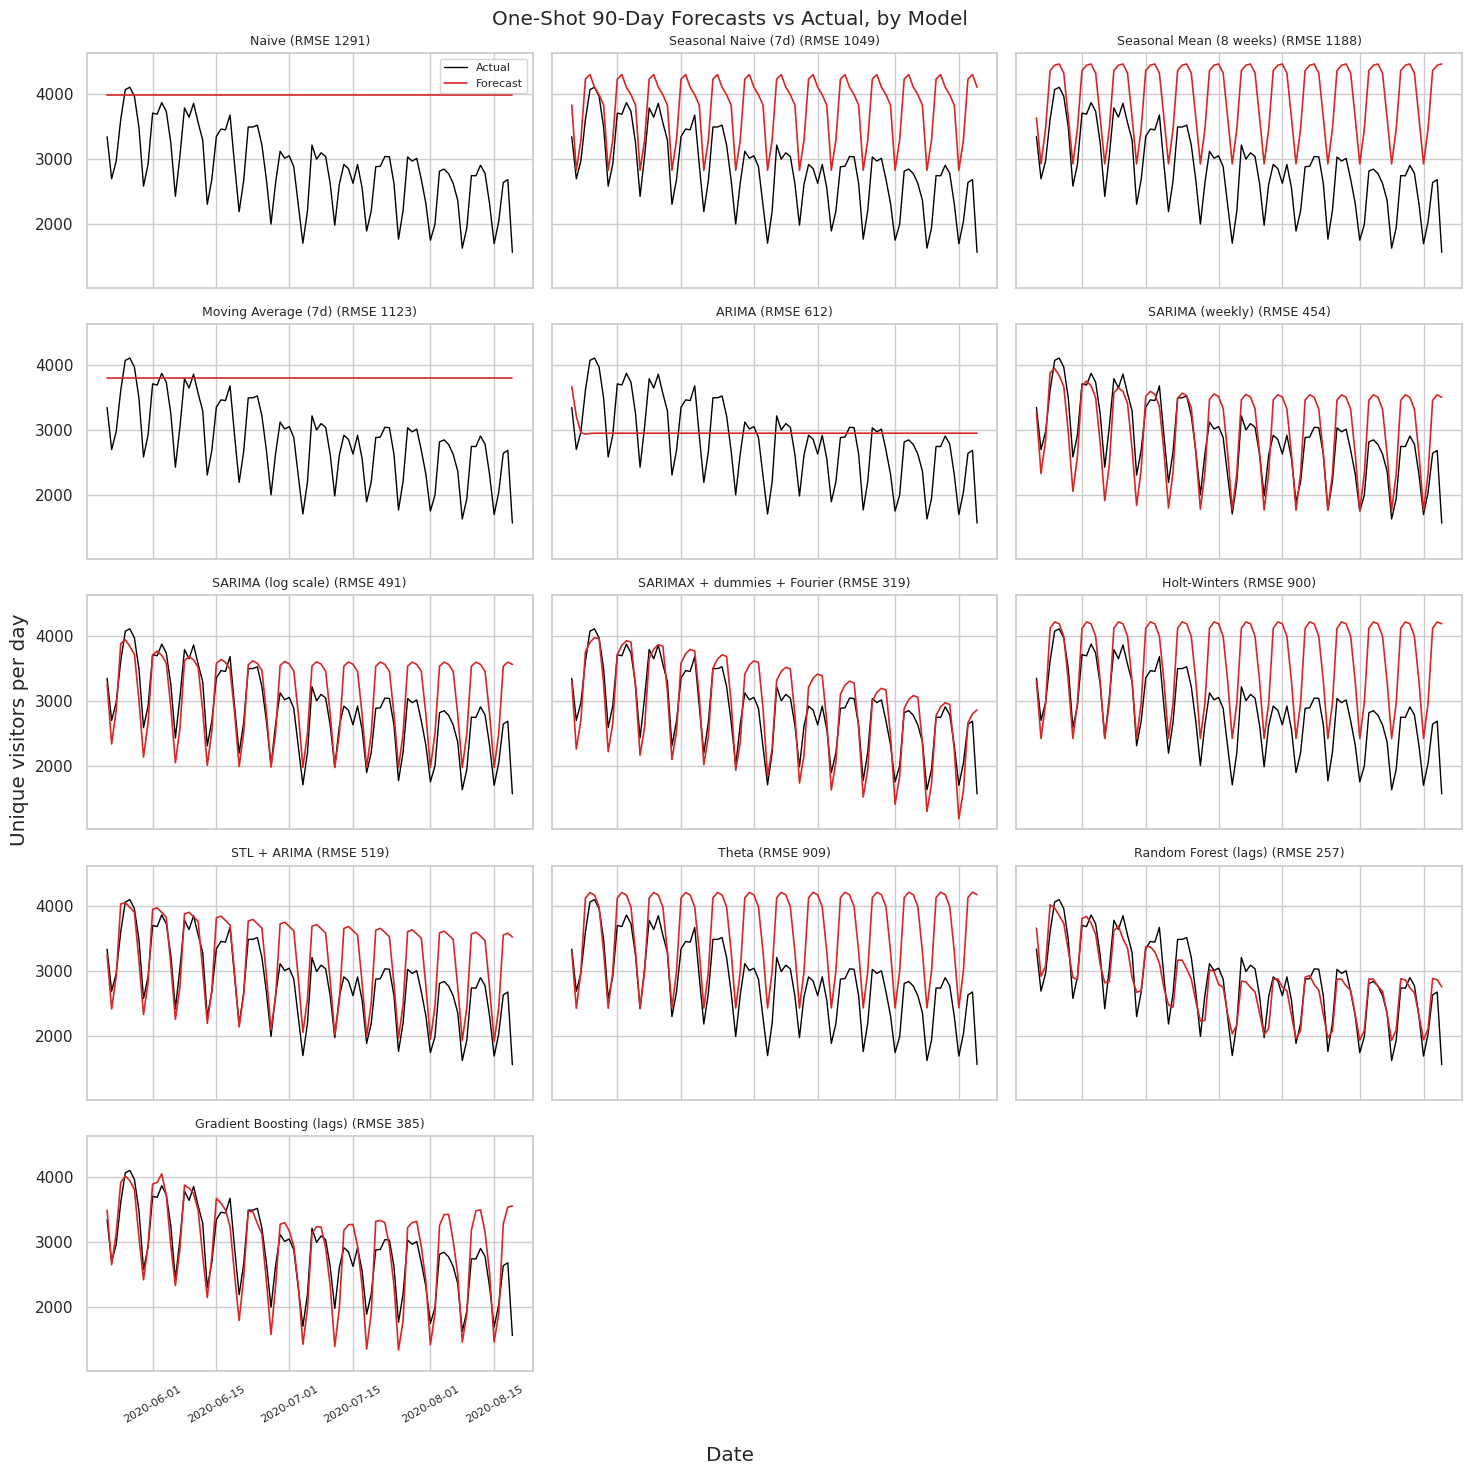

In [44]:
def plot_model_grid(test_data, forecasts, scores, n_columns=3, filename=None):
    """One panel per model: actual test values versus that model's forecast."""
    n_models = len(forecasts)
    n_rows = int(np.ceil(n_models / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 3.0 * n_rows), sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()

    for ax, (name, frame) in zip(axes, forecasts.items()):
        ax.plot(test_data, color="black", linewidth=1.0, label="Actual")
        ax.plot(frame["forecast"], color="tab:red", linewidth=1.2, label="Forecast")
        ax.set_title(f"{name} (RMSE {scores.loc[name, 'RMSE']:.0f})", fontsize=9)
        ax.tick_params(axis="x", rotation=30, labelsize=8)
    for ax in axes[n_models:]:
        ax.set_visible(False)

    axes[0].legend(loc="best", fontsize=8)
    fig.supxlabel("Date")
    fig.supylabel("Unique visitors per day")
    fig.suptitle("One-Shot 90-Day Forecasts vs Actual, by Model")
    finish_plot(filename)


plot_model_grid(test, test_forecasts, results_oneshot, filename="16_model_grid")

Three lowest rolling-origin RMSE: ['Random Forest (lags)', 'STL + ARIMA', 'Gradient Boosting (lags)']


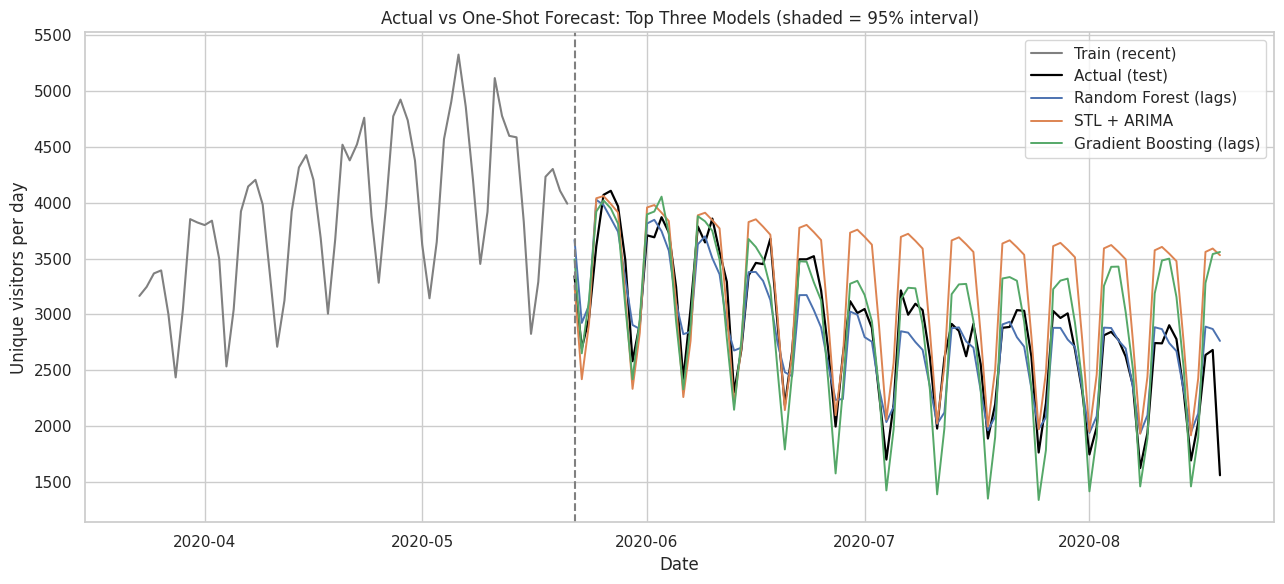

In [45]:
def plot_forecast_comparison(train_data, test_data, forecasts, model_names,
                             history_days=60, filename=None):
    """Plot recent training data, actual test data and selected model forecasts."""
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.plot(train_data.iloc[-history_days:], color="grey", label="Train (recent)")
    ax.plot(test_data, color="black", linewidth=1.6, label="Actual (test)")

    for name in model_names:
        frame = forecasts[name]
        line, = ax.plot(frame["forecast"], linewidth=1.4, label=name)
        if {"lower", "upper"}.issubset(frame.columns):
            ax.fill_between(frame.index, frame["lower"], frame["upper"],
                            color=line.get_color(), alpha=0.10)

    ax.axvline(test_data.index[0], color="grey", linestyle="--")
    ax.set_title("Actual vs One-Shot Forecast: Top Three Models (shaded = 95% interval)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Unique visitors per day")
    ax.legend()
    finish_plot(filename)


top_three_models = results_rolling["RMSE"].nsmallest(3).index.tolist()
print("Three lowest rolling-origin RMSE:", top_three_models)
plot_forecast_comparison(train, test, test_forecasts, top_three_models, filename="17_top_models")

### Interpretation

- **Flat-line models** cut through the weekly pattern and miss every weekday/weekend swing.
- **Seasonal models** reproduce the weekly rhythm; their remaining errors come from day-to-day random variation, changes in the overall level and unusual days.
- Over a **90-day one-shot horizon**, a model that gets the *level* slightly wrong will be wrong for the whole period, so differences between top models are often about level, not about the weekly shape.
- **Prediction intervals** should contain most actual points. Intervals from models with differencing widen as the horizon grows. If many points fall outside, the model is overconfident.

## 18. Residual Analysis

**Concept:** A residual is `actual − forecast`. If a model has captured all predictable structure, its residuals should look like random noise:

- centred around **zero**,
- **constant spread** over time,
- roughly **bell-shaped**,
- **no autocorrelation**, especially none at lag 7.

**Why:** Remaining structure means unused information. The assumptions behind prediction intervals also depend on these properties.

We analyse the **rolling-origin** residuals of the selected model (14-day-ahead errors), which are more relevant than errors 90 days ahead. The Ljung-Box test checks for autocorrelation (H0: none up to the given lag). We also check **interval calibration**: the share of actual values inside the 95% interval should be close to 95%.

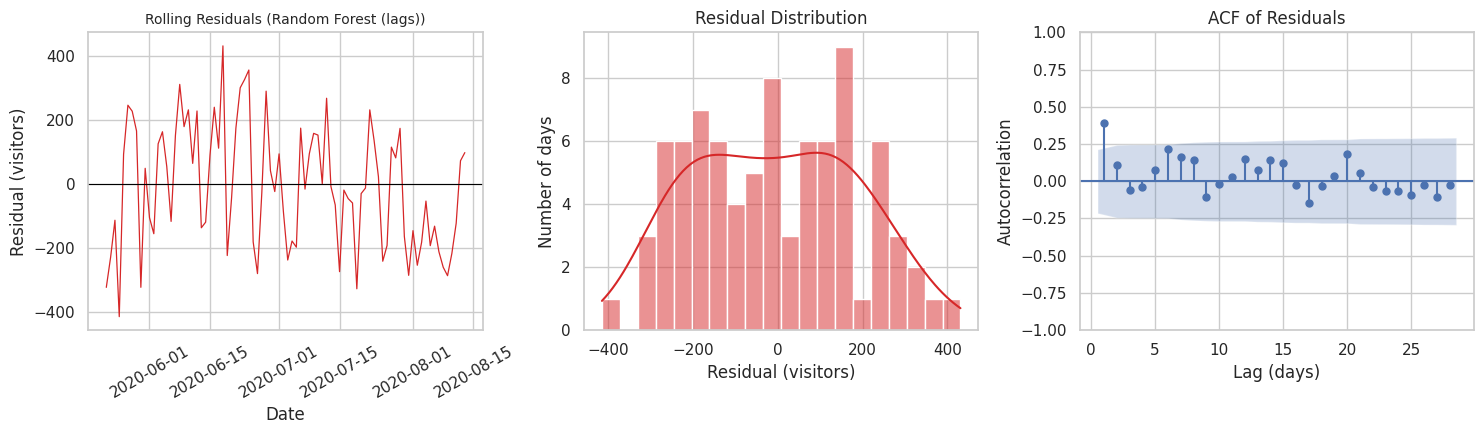

Mean residual (bias): -10.0 visitors
Residual std        : 193.8 visitors


,lb_stat,lb_pvalue
7,22.096786,0.002445
14,30.126402,0.007332
21,38.428346,0.011477


The selected model does not provide native prediction intervals.


In [46]:
residuals = rolling_actual - rolling_forecasts[selected_model_name]["forecast"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].plot(residuals, color="tab:red", linewidth=0.9)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title(f"Rolling Residuals ({selected_model_name})", fontsize=10)
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Residual (visitors)")
axes[0].tick_params(axis="x", rotation=30)

sns.histplot(residuals, bins=20, kde=True, color="tab:red", ax=axes[1])
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual (visitors)")
axes[1].set_ylabel("Number of days")

plot_acf(residuals, lags=28, ax=axes[2], zero=False)
axes[2].set_title("ACF of Residuals")
axes[2].set_xlabel("Lag (days)")
axes[2].set_ylabel("Autocorrelation")
finish_plot("18_residual_analysis")

print(f"Mean residual (bias): {residuals.mean():.1f} visitors")
print(f"Residual std        : {residuals.std():.1f} visitors")
display(acorr_ljungbox(residuals, lags=[7, 14, 21]))

selected_frame = rolling_forecasts[selected_model_name]
if {"lower", "upper"}.issubset(selected_frame.columns):
    inside = ((rolling_actual >= selected_frame["lower"]) & (rolling_actual <= selected_frame["upper"])).mean()
    print(f"95% interval coverage on rolling forecasts: {inside * 100:.1f}%")
else:
    print("The selected model does not provide native prediction intervals.")

### Interpretation

- **Mean residual:** the average bias. Close to zero means no systematic over- or under-forecasting.
- **Residuals over time:** long runs above or below zero show the model drifting away from the true level for weeks.
- **Distribution:** a roughly symmetric shape supports interval assumptions. Count data often produces a few large positive residuals (unexpected traffic spikes).
- **ACF and Ljung-Box:** a significant spike at **lag 7** would mean weekly structure is still unexplained. Other significant lags indicate remaining short-term dependence. With 84 residuals, the tests have limited power.
- **Coverage:** much lower than 95% means the intervals are too narrow (overconfident). Much higher means they are too wide.

## 19. Future Forecast

**Selected model:** the one with the lowest rolling-origin RMSE (rule documented in section 16).

**Horizon:** the data ends in August 2020, and the data is daily, so we forecast the **next 28 days** (four full weeks). Forecast errors grow with the horizon, so the 28-day errors should be expected to exceed the 14-day rolling-origin scores.

The model is **re-fitted on the entire dataset** (train + test) so that it uses all available information.

**Prediction interval:** if the selected model provides a native interval, we use it. If not, we build an **empirical 95% interval** from the rolling-origin residuals of that model: the forecast plus the 2.5% and 97.5% quantiles of the residuals. This assumes errors have a similar size at every horizon, which is an approximation, since real errors grow with the horizon.

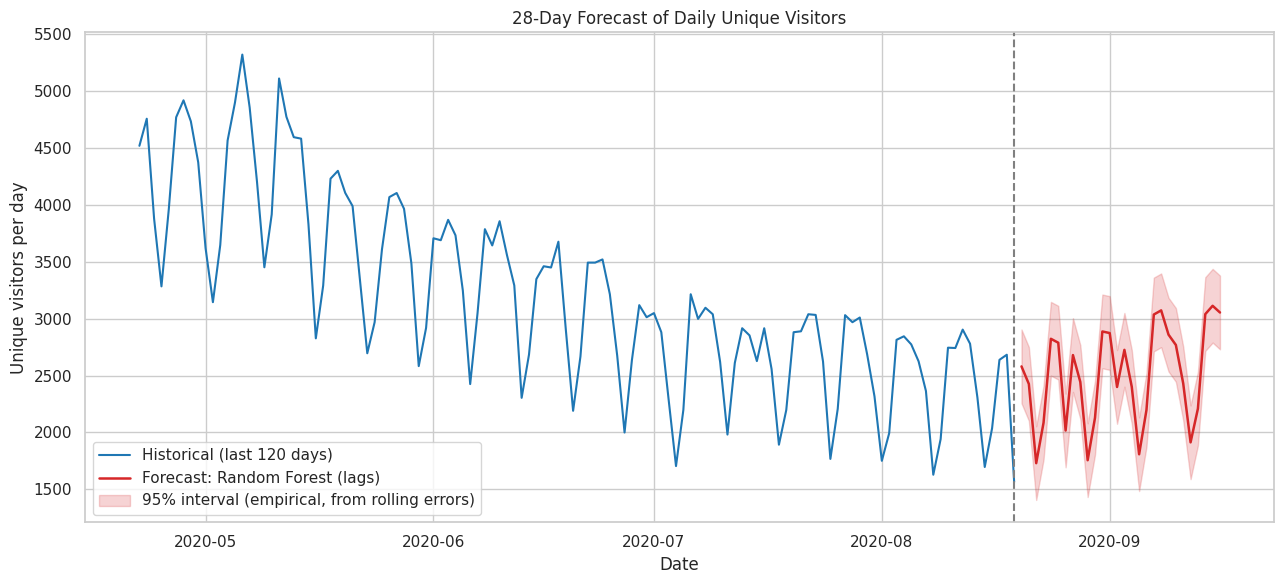

,weekday,forecast,lower,upper
2020-08-20,Thursday,2580,2257,2905
2020-08-21,Friday,2426,2102,2750
2020-08-22,Saturday,1729,1406,2054
2020-08-23,Sunday,2085,1762,2410
2020-08-24,Monday,2823,2499,3148
2020-08-25,Tuesday,2789,2465,3113
2020-08-26,Wednesday,2016,1693,2341
2020-08-27,Thursday,2680,2356,3004
2020-08-28,Friday,2444,2120,2768
2020-08-29,Saturday,1755,1432,2080


In [47]:
selected_forecaster = MODEL_FORECASTERS[selected_model_name]

future_index = pd.date_range(
    start=full_series.index[-1] + pd.Timedelta(days=1), periods=FORECAST_HORIZON_DAYS, freq="D"
)
future_forecast = selected_forecaster(full_series, future_index)

if {"lower", "upper"}.issubset(future_forecast.columns):
    interval_label = "95% prediction interval (model-based)"
else:
    lower_q, upper_q = residuals.quantile([ALPHA / 2, 1 - ALPHA / 2])
    future_forecast["lower"] = (future_forecast["forecast"] + lower_q).clip(lower=0)
    future_forecast["upper"] = future_forecast["forecast"] + upper_q
    interval_label = "95% interval (empirical, from rolling errors)"

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(full_series.iloc[-120:], color="tab:blue", label="Historical (last 120 days)")
ax.plot(future_forecast["forecast"], color="tab:red", linewidth=1.8,
        label=f"Forecast: {selected_model_name}")
ax.fill_between(future_forecast.index, future_forecast["lower"], future_forecast["upper"],
                color="tab:red", alpha=0.2, label=interval_label)
ax.axvline(full_series.index[-1], color="grey", linestyle="--")
ax.set_title(f"{FORECAST_HORIZON_DAYS}-Day Forecast of Daily Unique Visitors")
ax.set_xlabel("Date")
ax.set_ylabel("Unique visitors per day")
ax.legend()
finish_plot("19_future_forecast")

forecast_table = future_forecast.round(0).astype(int)
forecast_table.insert(0, "weekday", future_forecast.index.day_name())
display(forecast_table.head(14))

### Interpretation

- The forecast should reproduce the **weekly rhythm** seen in the data: weekdays above weekends if the weekday effect found earlier holds.
- The **level** of the forecast is anchored to recent observations. Trends and time-of-year changes beyond the data are only partly captured.
- The **interval** is wide because daily traffic is noisy, and it should be used to judge what is *unusual*: a day outside the interval deserves attention, a day inside it is within normal variation.
- **Forecasts are estimates, not certainties.** Marketing events, links from other sites, changes in the academic calendar or tracking changes can push traffic outside the interval.

## 20. Business / Practical Interpretation

Based on this dataset (traffic of a teaching-notes website), a daily visitor forecast with an uncertainty range could support:

- **Capacity planning:** knowing which days are expected to be busiest helps decide how much server capacity or bandwidth is needed, and the upper interval bound gives a sensible planning ceiling.
- **Scheduling maintenance and releases:** planned downtime or site updates can be placed on the days the forecast expects to be quietest.
- **Anomaly monitoring:** actual traffic falling outside the 95% interval can trigger an alert, which helps to spot tracking failures or unexpected spikes early.
- **Content planning:** the weekday profile shows when readers are most active, so publishing can be timed for those days.

**What the forecast cannot do:** it does not know about specific events (a link shared widely, a course starting, a site redesign). It also has no information on revenue or conversions, because the dataset contains only traffic counts, so no financial claims can be made.

## 21. Key Findings

The summary below is generated from the results of this run, so the numbers always match the notebook.

In [48]:
print("KEY FINDINGS")
print("=" * 60)
print(f"Training data : {len(train)} days ({train.index[0].date()} to {train.index[-1].date()})")
print(f"Test data     : {len(test)} days ({test.index[0].date()} to {test.index[-1].date()})")

print("\nTrend")
print("  Average daily unique visitors per complete year: "
      + ", ".join(f"{year}: {value:,.0f}" for year, value in yearly_mean.items()))
print(f"  Trend strength (daily decomposition): {trend_strength:.2f}")

print("\nWeekly pattern")
print(f"  Busiest weekday (average): {weekday_mean.idxmax()} ({weekday_mean.max():,.0f})")
print(f"  Quietest weekday (average): {weekday_mean.idxmin()} ({weekday_mean.min():,.0f})")
print(f"  Weekend vs weekday difference: {(weekend_mean / weekday_only_mean - 1) * 100:+.1f}%")
print(f"  Weekly seasonal strength: {weekly_seasonal_strength:.2f}")

print("\nYearly pattern")
print(f"  Busiest month on average (complete months): month {monthly_climatology.idxmax()}")
print(f"  Quietest month on average (complete months): month {monthly_climatology.idxmin()}")
print(f"  Yearly seasonal strength (weekly data): {yearly_seasonal_strength:.2f}")

print("\nStationarity and differencing")
print(f"  ADF p-values: original {adf_p_original:.4f} | first diff {adf_p_diff:.4f} | "
      f"seasonal diff {adf_p_seasonal:.4f} | both {adf_p_both:.4f}")
print(f"  ARIMA d = {d_order}; SARIMA d = {d_sarima}, D = {D_seasonal}")
print(f"  Selected SARIMA: {sarima_order} x {sarima_seasonal_order}")

print("\nModel comparison (sorted by rolling-origin RMSE)")
display(comparison.round(2))
print(f"Selected model: {selected_model_name}")
print(f"Models not significantly different from it (DM p >= {ALPHA}): "
      + (", ".join(not_different) if not_different else "none"))
print(f"Mean rolling-origin bias of the selected model: {residuals.mean():.1f} visitors")

KEY FINDINGS
Training data : 2077 days (2014-09-14 to 2020-05-21)
Test data     : 90 days (2020-05-22 to 2020-08-19)

Trend
  Average daily unique visitors per complete year: 2015: 2,908, 2016: 3,200, 2017: 2,462, 2018: 3,055, 2019: 3,056
  Trend strength (daily decomposition): 0.92

Weekly pattern
  Busiest weekday (average): Tuesday (3,555)
  Quietest weekday (average): Saturday (1,775)
  Weekend vs weekday difference: -37.8%
  Weekly seasonal strength: 0.90

Yearly pattern
  Busiest month on average (complete months): month 4
  Quietest month on average (complete months): month 7
  Yearly seasonal strength (weekly data): 0.89

Stationarity and differencing
  ADF p-values: original 0.0003 | first diff 0.0000 | seasonal diff 0.0000 | both 0.0000
  ARIMA d = 0; SARIMA d = 0, D = 1
  Selected SARIMA: (2, 0, 1) x (1, 1, 1, 7)

Model comparison (sorted by rolling-origin RMSE)


90-day one-shot                             \
                                        MAE     RMSE MAPE (%)     Bias   
Model                                                                    
Random Forest (lags)                 196.84   257.03     7.47    35.68   
STL + ARIMA                          409.89   518.88    15.58  -356.94   
Gradient Boosting (lags)             284.85   385.08    11.32   -47.18   
SARIMA (log scale)                   391.71   490.76    15.06  -252.79   
SARIMA (weekly)                      354.44   453.61    13.37  -152.01   
Seasonal Naive (7d)                  945.44  1049.10    36.93  -945.44   
Theta                                770.70   908.53    29.60  -755.21   
Holt-Winters                         760.58   899.69    29.17  -743.19   
SARIMAX + dummies + Fourier          249.84   319.44     9.78   -73.81   
Moving Average (7d)                  967.25  1122.93    40.63  -947.60   
ARIMA                                484.27   612.16    19.46  -109.81   
Naive                               1145.62  1290.59    47.40 -1141.31   
Seasonal Mean (8 weeks)             1091.96  1188.17    42.05 -1091.96   

                            14-day rolling origin                           
                                              MAE    RMSE MAPE (%)    Bias  
Model                                                                       
Random Forest (lags)                       164.78  192.89     5.92   -9.95  
STL + ARIMA                                162.66  213.73     5.86  -65.47  
Gradient Boosting (lags)                   176.32  215.02     6.27  -36.51  
SARIMA (log scale)                         200.99  256.21     7.07  -76.01  
SARIMA (weekly)                            215.95  266.51     7.81    7.80  
Seasonal Naive (7d)                        221.60  279.54     7.95 -172.33  
Theta                                      259.78  332.48     9.68  -31.68  
Holt-Winters                               262.01  337.17     9.84  -17.56  
SARIMAX + dummies + Fourier                322.69  406.91    12.27   83.93  
Moving Average (7d)                        378.34  490.42    15.28 -172.33  
ARIMA                                      453.32  572.65    17.26  -60.76  
Naive                                      476.74  639.73    19.36 -415.71  
Seasonal Mean (8 weeks)                    609.79  656.70    21.85 -609.79

Selected model: Random Forest (lags)
Models not significantly different from it (DM p >= 0.05): SARIMA (log scale), Gradient Boosting (lags), STL + ARIMA
Mean rolling-origin bias of the selected model: -10.0 visitors


### Summary

- **Weekly seasonality** is the dominant short-term structure; the weekday effect is strong and stable.
- **Trend and yearly effects** exist but are weaker and harder to estimate from five years.
- **Stationarity:** the data needs differencing and/or seasonal terms; the rules in section 11 decided the orders, not model scores.
- **Models:** those with weekly components clearly beat the ones without. Among the strongest models the differences may be small, and the Diebold-Mariano test shows which are statistically distinguishable.
- **Forecast behaviour:** the 28-day forecast keeps the weekly rhythm; the interval is wide because daily traffic is noisy.

## 22. Limitations

- **One site, one series:** results may not transfer to websites with different audiences or traffic sources.
- **Short test window:** 90 days is one part of the year, so time-of-year effects are only partly tested. The last months of the data fall in 2020, when many courses moved online; the dataset does not document whether this changed traffic, so the test window may contain unusual behaviour.
- **Unpredictable events:** spikes from shared links, outages and tracking changes cannot be forecast.
- **Fixed model orders during rolling refits:** only parameters were re-estimated. Re-selecting orders at each origin would be more expensive and could change the ranking.
- **Interval approximations:** native intervals assume normal, constant-variance errors; the empirical fallback assumes errors do not grow with the horizon.
- **Untuned machine-learning models**, and recursive forecasting accumulates errors over long horizons.
- **Multiple testing:** the Diebold-Mariano p-values come from several comparisons against one reference model.
- **Data quality:** the data is an export from a single analytics system. The definition of a "unique visit" depends on IP addresses and cookies, which can be affected by shared networks and privacy settings.

## 23. Conclusion

This project applied an intermediate time-series workflow to daily website traffic. The data was cleaned (numbers stored as text, standardised column names), split chronologically before any exploration, and analysed at two seasonal scales: weekly and yearly. Differencing decisions followed rules fixed in advance, SARIMA orders were chosen by a small AIC search, and 13 models, from simple baselines to SARIMA, Holt-Winters, STL, Theta, regression with ARIMA errors and machine learning, were compared with both a one-shot hold-out and a **rolling-origin evaluation**. A **Diebold-Mariano test** then checked which differences were meaningful, residuals and interval coverage were examined, and the selected model produced a 28-day forecast with uncertainty.

The main lessons are that **seasonality must be modelled at the right scale** (here weekly), that **rolling-origin evaluation and significance tests give more trustworthy conclusions than a single hold-out table**, and that a good forecast comes with an honest account of its uncertainty and limits.

**Next steps:** tune the machine-learning models with time-series cross-validation, add holiday and academic-calendar features, test a multiplicative seasonal model, and compare with Prophet or other libraries.